# Tema 2 Machine Learning - Images Classificator
## Mandescu Victor-Ioan 342C4

In [67]:
%pip install matplotlib
%pip install Pillow
%pip install torchvision
%pip install torch

from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch import device
from IPython import display
from sklearn.metrics import confusion_matrix

import time
import numpy as np
import os
import matplotlib.pyplot as plt
import random
import torch
import torchvision
import zipfile
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import seaborn as sns
import copy


In [68]:
path_to_zip_file = "/content/imagebits.zip"
directory_to_extract_to = "images"

if not os.path.exists(directory_to_extract_to):
    os.makedirs(directory_to_extract_to)

with zipfile.ZipFile(path_to_zip_file, 'r') as zip_ref:
    zip_ref.extractall(directory_to_extract_to)

## Exploratory data analysis for image classification - imagebits

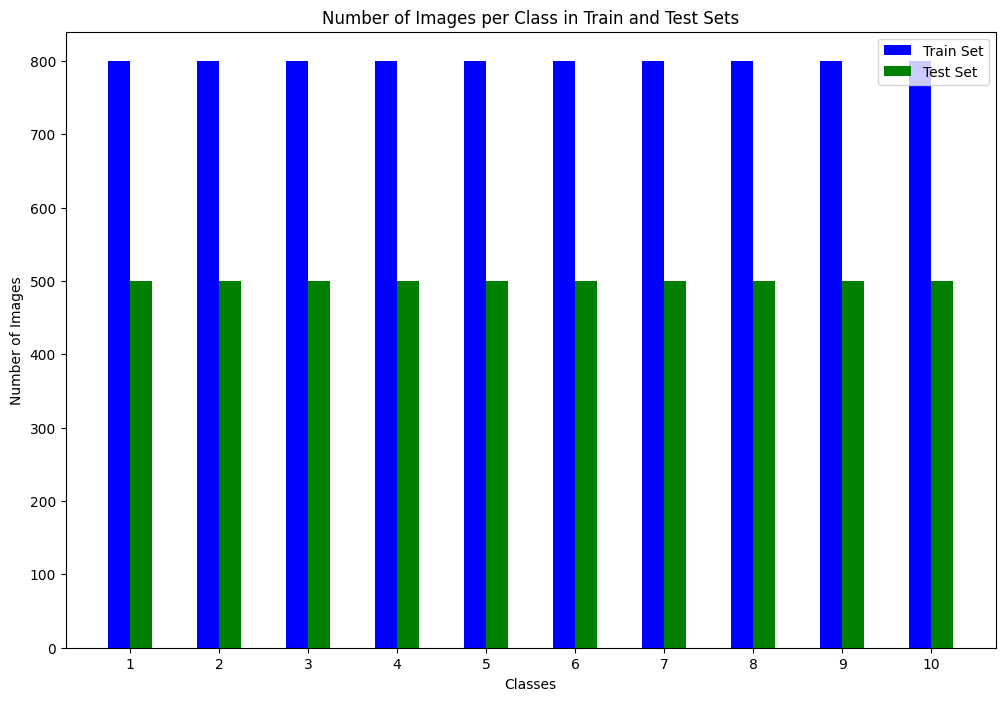

In [69]:
img_train_dir_path = 'images/imagebits/train/'
img_test_dir_path = 'images/imagebits/test/'
number_classes = {}

for i in range(1, 11):
    train_class_dir = os.path.join(img_train_dir_path, str(i))
    test_class_dir = os.path.join(img_test_dir_path, str(i))

    train_images = os.listdir(train_class_dir)
    test_images = os.listdir(test_class_dir)

    number_classes[i] = {'train_count': len(train_images), 'test_count': len(test_images)}

labels = list(number_classes.keys())
train_vals = []
test_vals = []

for v in number_classes.values():
    train_vals.append(v['train_count'])
    test_vals.append(v['test_count'])

x = np.arange(len(labels))
width = 0.25

fig = plt.subplots(figsize=(12, 8))
plt.bar(x - width/2, train_vals, width, label='Train Set', color='blue')
plt.bar(x + width/2, test_vals, width, label='Test Set', color='green')

plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train and Test Sets')
plt.xticks(x, labels)
plt.legend()
plt.show()

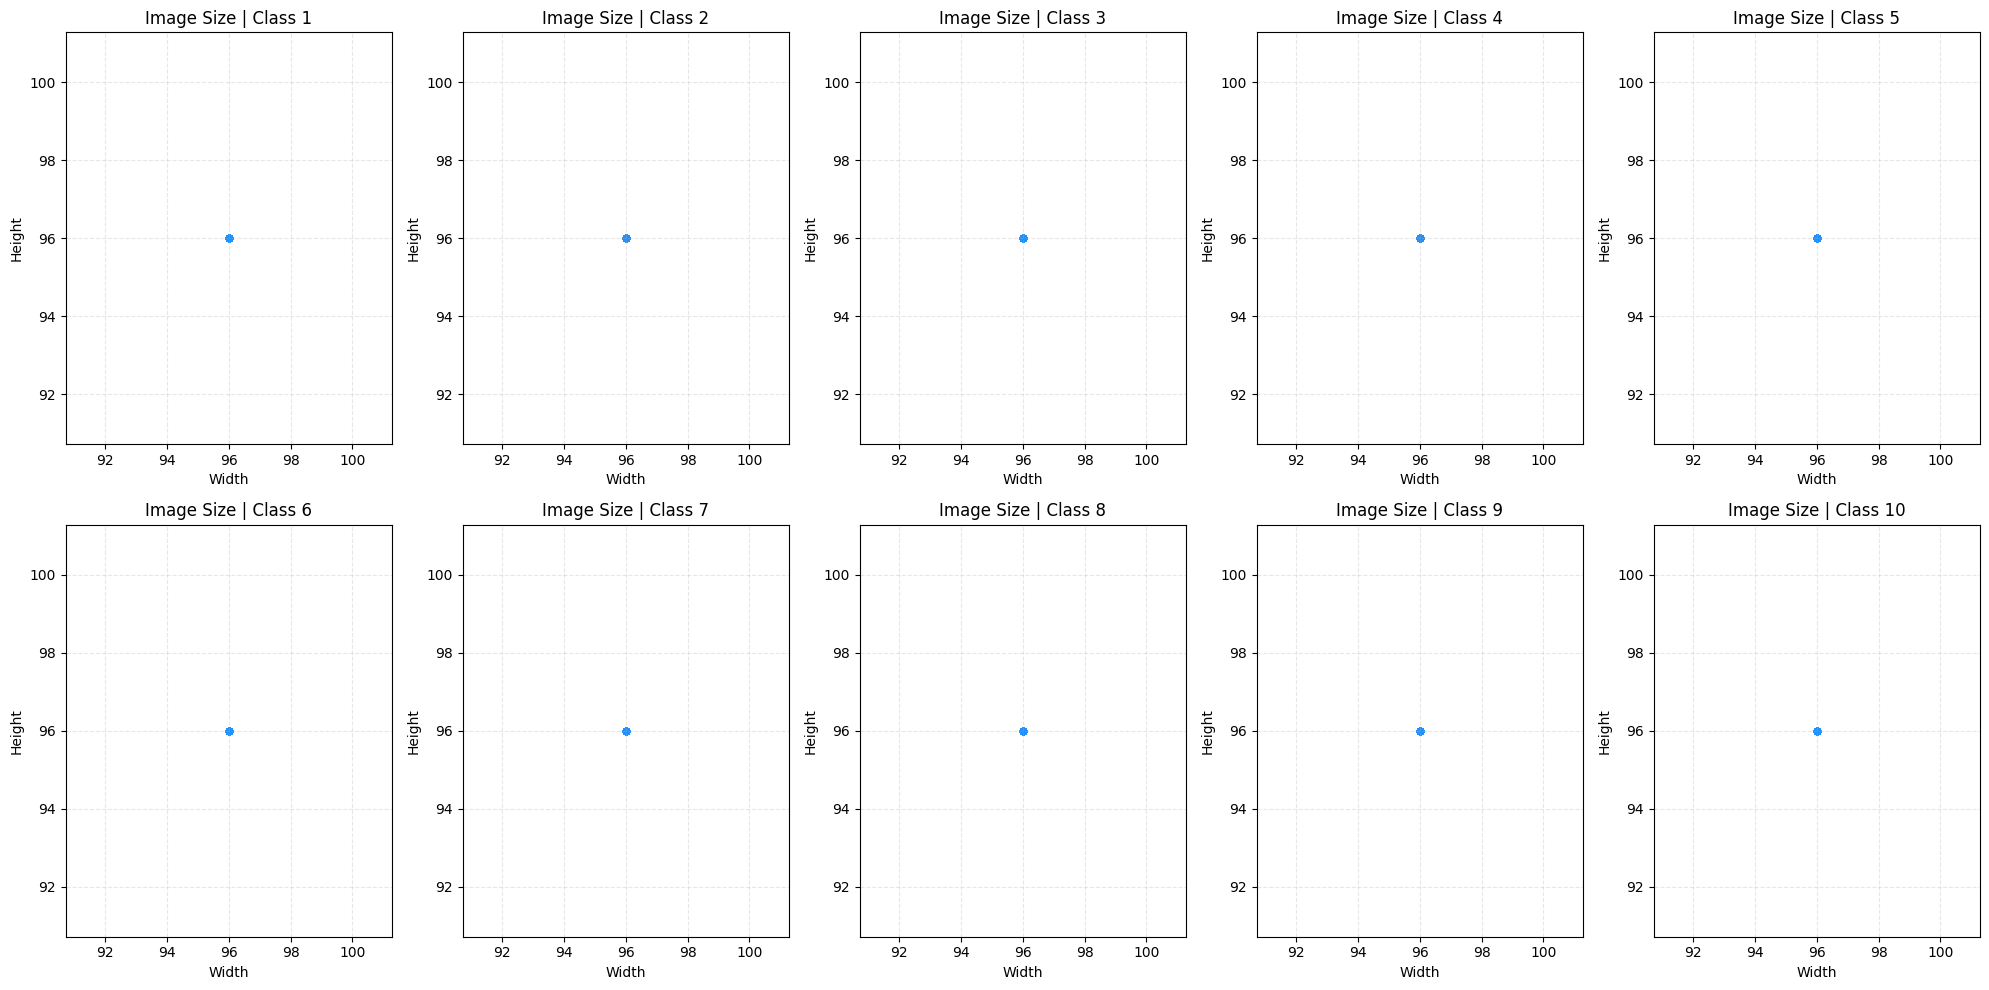

In [70]:
class_data = {}

for i in range(1, 11):
    class_dir = os.path.join(img_train_dir_path, str(i))
    images = os.listdir(class_dir)

    widths = []
    heights = []

    for img_name in images:
        if img_name.lower().endswith(('.png')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[i] = {'widths': widths, 'heights': heights}

fig, ax = plt.subplots(2, 5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    weight = class_data[class_id]['widths']
    height = class_data[class_id]['heights']

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].scatter(weight, height, alpha=0.5, s=20, color='dodgerblue')
    ax[row_idx, col_idx].set_title(f'Image Size | Class {class_id}')
    ax[row_idx, col_idx].set_xlabel('Width')
    ax[row_idx, col_idx].set_ylabel('Height')
    ax[row_idx, col_idx].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

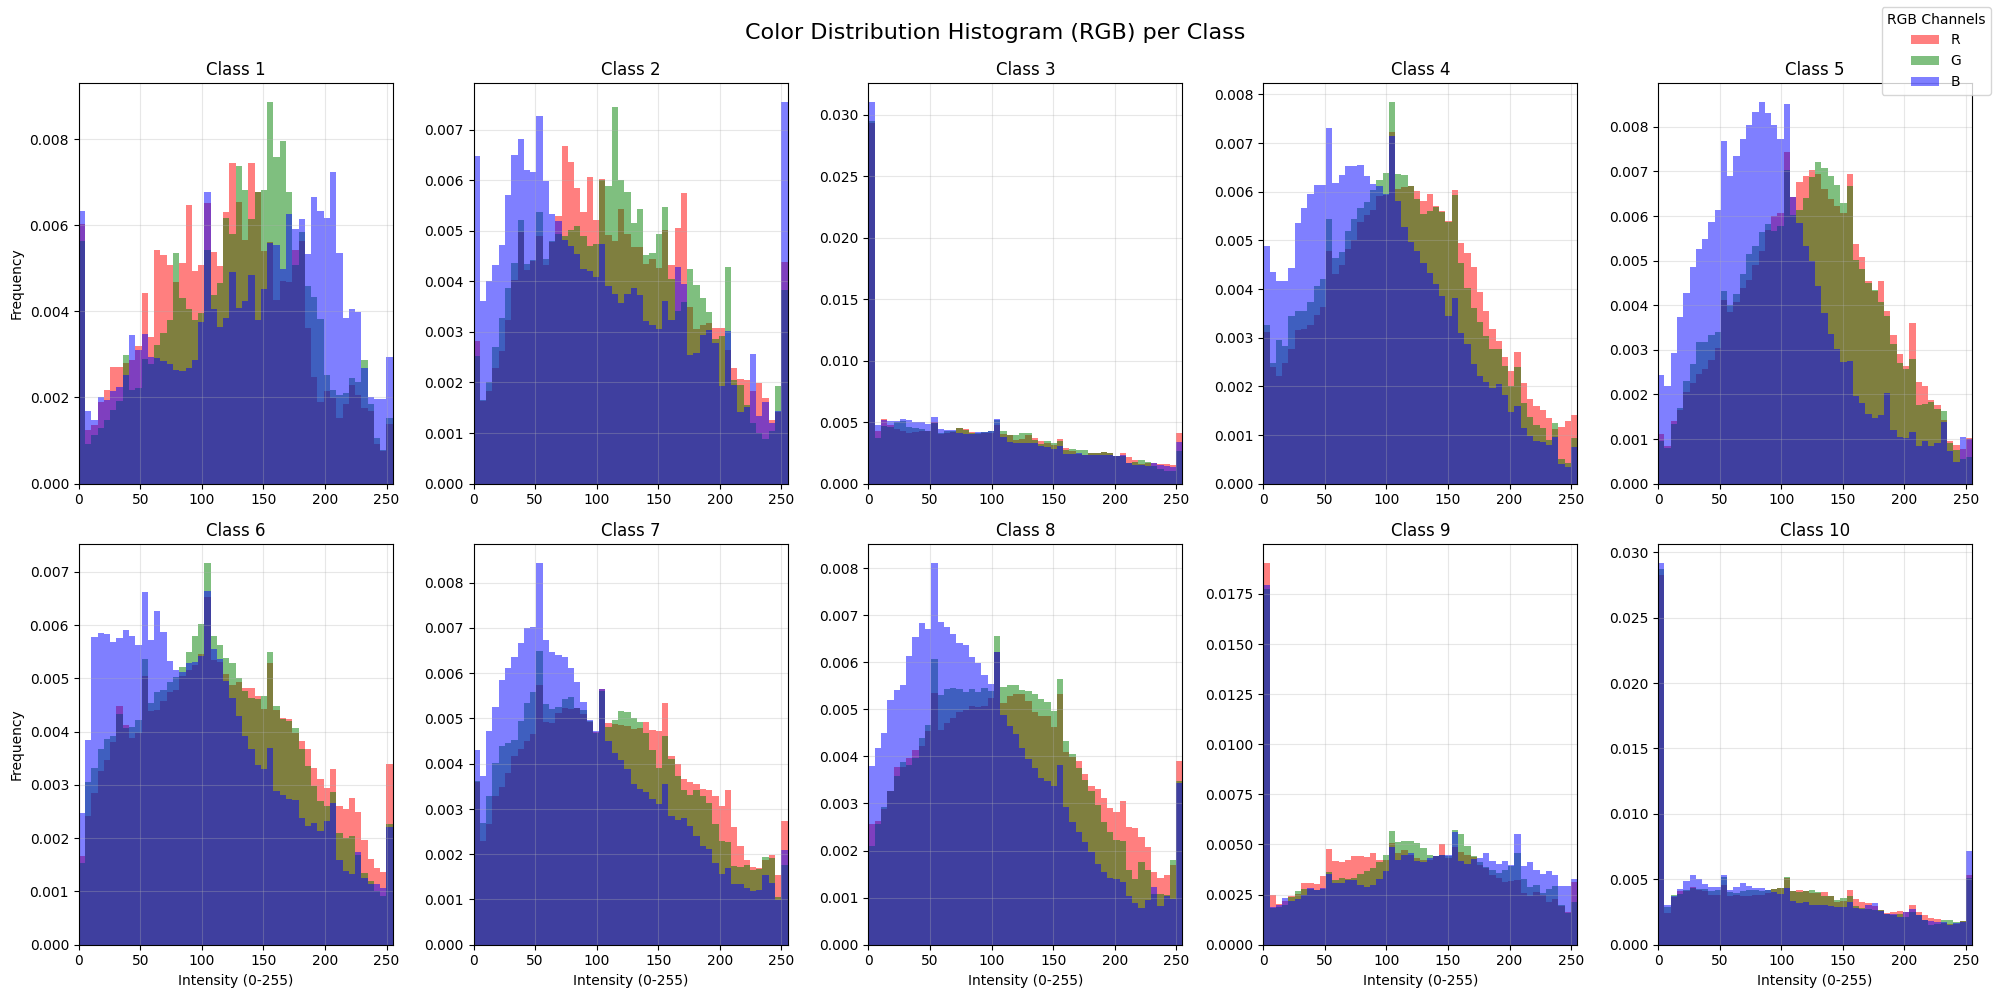

In [71]:
rgb_class = {}

for idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))

    images = os.listdir(class_dir)
    if len(images) > 100:
        images = images[:100]

    all_reds = []
    all_greens = []
    all_blues = []

    for img_name in images:
        if img_name.lower().endswith(('.png')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path).convert('RGB') as img:
                img_array = np.array(img)
                all_reds.extend(img_array[:, :, 0].flatten())
                all_greens.extend(img_array[:, :, 1].flatten())
                all_blues.extend(img_array[:, :, 2].flatten())

    rgb_class[class_id] = { 'red': all_reds, 'green': all_greens, 'blue': all_blues }


fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    red = rgb_class[class_id]["red"]
    green = rgb_class[class_id]["green"]
    blue = rgb_class[class_id]["blue"]

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].hist(red, bins=50, color='red', alpha=0.5, label='R', density=True)
    ax[row_idx, col_idx].hist(green, bins=50, color='green', alpha=0.5, label='G', density=True)
    ax[row_idx, col_idx].hist(blue, bins=50, color='blue', alpha=0.5, label='B', density=True)
    ax[row_idx, col_idx].set_title(f'Class {class_id}')
    ax[row_idx, col_idx].set_xlim(0, 255)

    if idx % 5 == 0:
        ax[row_idx, col_idx].set_ylabel('Frequency')
    if idx >= 5:
        ax[row_idx, col_idx].set_xlabel('Intensity (0-255)')

    ax[row_idx, col_idx].grid(True, alpha=0.3)

handles, labels = ax[row_idx, col_idx].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title="RGB Channels")

plt.suptitle("Color Distribution Histogram (RGB) per Class", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

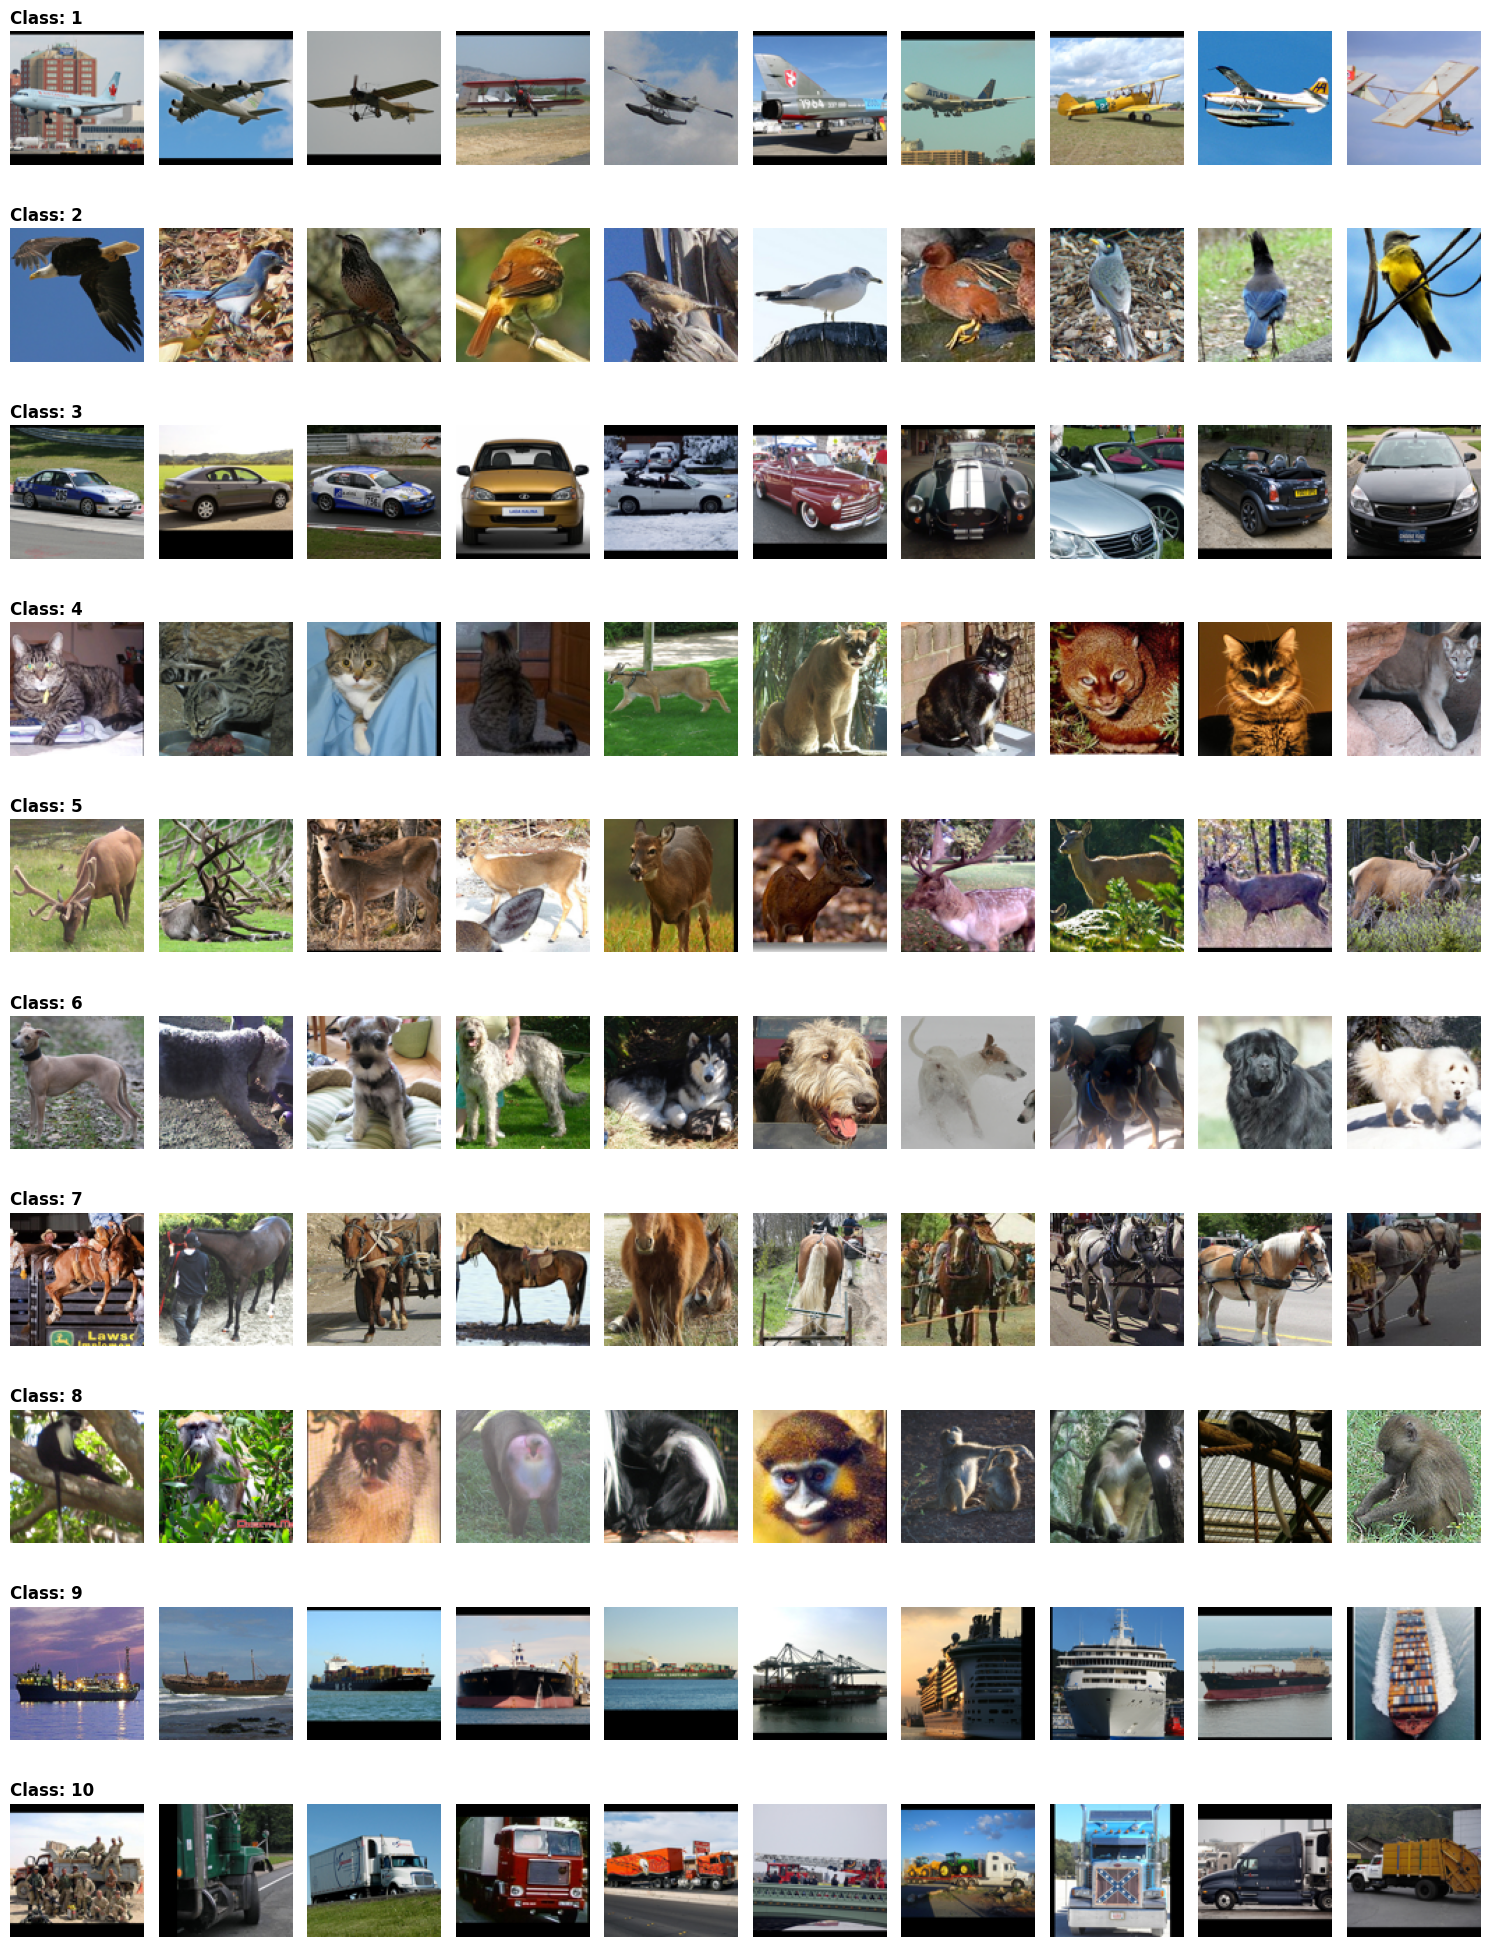

In [72]:
fig, ax = plt.subplots(10, 10, figsize=(15, 20))

for row_idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))
    all_imgs = []
    for f in os.listdir(class_dir):
      if f.lower().endswith(('.png')):
        all_imgs.append(f)

    current_samples = random.sample(all_imgs, min(len(all_imgs), 10))
    for col_idx, img_name in enumerate(current_samples):
        img_path = os.path.join(class_dir, img_name)
        with Image.open(img_path) as img:
            ax[row_idx, col_idx].imshow(img)
            ax[row_idx, col_idx].axis('off')

            if col_idx == 0:
                ax[row_idx, col_idx].set_title(f'Class: {class_id}', fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

In [73]:
if torch.cuda.is_available():
  device = torch.device("cuda")
else:
  device = torch.device("cpu")

print(f"Running on device: {device}")

train_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_transform_aug = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_images_aug = torchvision.datasets.ImageFolder(root=img_train_dir_path, transform=train_transform_aug)
train_images = torchvision.datasets.ImageFolder(root=img_train_dir_path, transform=train_transform)
test_images = torchvision.datasets.ImageFolder(root=img_test_dir_path, transform=test_transform)

print(f'Size of training labels {len(train_images.targets)}')
print(f'Size of test labels {len(test_images.targets)}')

Running on device: cuda
Size of training labels 8000
Size of test labels 5000


In [74]:
BATCH_SIZE_TRAIN = 64
BATCH_SIZE_TEST = 64
NO_WORKERS = 8
SHUFFLE_DATA = True

train_loader = torch.utils.data.DataLoader(train_images, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_images, batch_train_labels) = next(iter(train_loader))

print(f'Shape of training images: {batch_train_images.size()}')
print(f'Shape of training labels: {batch_train_labels.size()}')

train_loader_aug = torch.utils.data.DataLoader(train_images_aug, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_images_aug, batch_train_labels_aug) = next(iter(train_loader_aug))
print(f'Shape of augmented training images: {batch_train_images_aug.size()}')
print(f'Shape of augmented training labels: {batch_train_labels_aug.size()}')

Shape of training images: torch.Size([64, 3, 96, 96])
Shape of training labels: torch.Size([64])
Shape of augmented training images: torch.Size([64, 3, 96, 96])
Shape of augmented training labels: torch.Size([64])


In [75]:
test_loader = torch.utils.data.DataLoader(test_images, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)

def loopy_test_loader(dl):
    data_iter = iter(dl)

    while True:
        try:
            yield next(data_iter)
        except StopIteration:
            data_iter = iter(dl)
            yield next(data_iter)

(batch_test_images, batch_test_labels) = next(iter(test_loader))
print(f'Shape of test images: {batch_test_images.size()}')
print(f'Shape of test labels: {batch_test_labels.size()}')

Shape of test images: torch.Size([64, 3, 96, 96])
Shape of test labels: torch.Size([64])


In [76]:
def plot_losses(loss_list, steps, ct):
    if ct % 1000 == 0:
        display.clear_output(wait=True)

    display.display(plt.gcf())
    plt.plot(steps, loss_list, c='b')
    time.sleep(1.0)

def get_num_params(model):
    num_params = 0
    for params in model.parameters():
        num_params += params.shape.numel()

    return num_params

def top_k_accuracy(k, target, output):
    batch_size = target.size(0)

    _, pred = output.topk(k, 1, True, True)

    pred = pred.t()
    correct = pred.eq(target.to(device).view(1, -1).expand_as(pred))

    correct_k = correct[:k].view(-1).float().sum(0, keepdim=True)
    correct_k.mul_(100.0 / batch_size)

    return correct_k

In [77]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, img_size = 96, hidden_size=512, out_size=256, num_classes=10):
        super(MLP, self).__init__()

        self.in_size = 3 * img_size * img_size

        self.fc1 = nn.Linear(self.in_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, out_size)
        self.fc3 = nn.Linear(out_size, num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [78]:
import torch
import torch.nn as nn

class MiniVGG(nn.Module):
    def __init__(self, num_classes=10, in_size=512, hidden_size1=1024, hidden_size2=1024, use_batch_norm=False, dropout_val=0.5):
        super(MiniVGG, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn1 = nn.BatchNorm2d(64)
        else:
            self.bn1 = nn.Identity()

        self.conv2 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn2 = nn.BatchNorm2d(64)
        else:
            self.bn2 = nn.Identity()

        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn3 = nn.BatchNorm2d(128)
        else:
            self.bn3 = nn.Identity()

        self.conv4 = nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn4 = nn.BatchNorm2d(128)
        else:
            self.bn4 = nn.Identity()

        self.conv5 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn5 = nn.BatchNorm2d(256)
        else:
            self.bn5 = nn.Identity()

        self.conv6 = nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn6 = nn.BatchNorm2d(256)
        else:
            self.bn6 = nn.Identity()

        self.conv7 = nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn7 = nn.BatchNorm2d(512)
        else:
            self.bn7 = nn.Identity()

        self.conv8 = nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn8 = nn.BatchNorm2d(512)
        else:
            self.bn8 = nn.Identity()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        flatten_size = in_size * 7 * 7

        self.fc1 = nn.Linear(in_features=flatten_size, out_features=hidden_size1)
        self.fc2 = nn.Linear(in_features=hidden_size1, out_features=hidden_size2)
        self.fc3 = nn.Linear(in_features=hidden_size2, out_features=num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout_val)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        x = self.relu(self.bn3(self.conv3(x)))
        x = self.relu(self.bn4(self.conv4(x)))
        x = self.pool(x)

        x = self.relu(self.bn5(self.conv5(x)))
        x = self.relu(self.bn6(self.conv6(x)))
        x = self.pool(x)

        x = self.relu(self.bn7(self.conv7(x)))
        x = self.relu(self.bn8(self.conv8(x)))
        x = self.pool(x)

        x = self.avgpool(x)
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [79]:
EPOCHS = 50
TRAIN_ITERS = 100e3
REPORT_TRAIN_EVERY = 100
PLOT_EVERY = 100
REPORT_TEST_EVERY = 200
TEST_ITERS = 100

criterion = nn.CrossEntropyLoss()

def train_engine(net, train_data_loader, optimizer, scheduler, num_epochs=35, name="Experiment"):
    history = {
        'train_loss': [], 'train_acc': [], 'train_steps': [],
        'val_loss': [], 'val_acc': [], 'val_steps': []
    }

    train_iter = 0
    running_loss = 0.0
    running_acc = 0.0

    test_data_provider = loopy_test_loader(test_loader)

    net.train()

    for epoch in range(num_epochs):
        for i, data in enumerate(train_data_loader, 0):

            inputs, labels = data[0].to(device), data[1].to(device)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            running_acc += top_k_accuracy(1, labels, outputs).item()

            # --- RAPORTARE TRAIN ---
            if train_iter % REPORT_TRAIN_EVERY == REPORT_TRAIN_EVERY - 1:
                train_loss = running_loss / REPORT_TRAIN_EVERY
                train_acc = running_acc / REPORT_TRAIN_EVERY

                print(f'[{name}] [Ep: {epoch+1}, Step: {train_iter}] Train Loss: {train_loss:.5f}, Acc: {train_acc:.2f}%')

                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['train_steps'].append(train_iter)

                running_loss = 0.0
                running_acc = 0.0

            if train_iter % REPORT_TEST_EVERY == 0:
                net.eval()
                with torch.no_grad():
                    test_iter = 0
                    test_loss_accum = 0.0
                    test_acc_accum = 0.0

                    while test_iter < TEST_ITERS:
                        try:
                            test_data = next(test_data_provider)
                        except StopIteration:
                            test_data_provider = loopy_test_loader(test_loader)
                            test_data = next(test_data_provider)

                        t_in, t_lbl = test_data[0].to(device), test_data[1].to(device)
                        t_out = net(t_in)

                        test_loss_accum += criterion(t_out, t_lbl).item()
                        test_acc_accum += top_k_accuracy(1, t_lbl, t_out).item()
                        test_iter += 1

                    avg_test_loss = test_loss_accum / TEST_ITERS
                    avg_test_acc = test_acc_accum / TEST_ITERS

                    print(f'>>> [{name} Val] Loss: {avg_test_loss:.5f}, Acc: {avg_test_acc:.2f}%')

                    history['val_loss'].append(avg_test_loss)
                    history['val_acc'].append(avg_test_acc)
                    history['val_steps'].append(train_iter)

                net.train()

            train_iter += 1

        scheduler.step()

    print(f"Finished: {name}")
    return history

In [80]:
# experiments = [
#     {
#         "name": "1_Base_Adam",
#         "hidden": 512,    # Configurația standard
#         "out": 256,
#         "opt": "adam",
#         "lr": 0.0005,
#         "wd": 1e-4
#     },
#     {
#         "name": "2_Wide_SGD",
#         "hidden": 2048,   # Arhitectură mai lată ("Wide")
#         "out": 512,
#         "opt": "sgd",     # Alt optimizator
#         "lr": 0.01,       # SGD cere LR mai mare
#         "wd": 1e-4
#     },
#     {
#         "name": "3_Small_RMSprop",
#         "hidden": 256,    # Arhitectură mai mică/rapidă
#         "out": 128,
#         "opt": "rmsprop", # Al treilea tip de optimizator
#         "lr": 0.00005,
#         "wd": 1e-4
#     }
# ]

# results_table = []
# best_acc = 0.0
# best_model_state = None
# best_model_name = ""
# best_config_hidden = 0
# best_config_out = 0

# print("🚀 START EXPERIMENTE CU CLASA MLP EXISTENTĂ...\n")

# for exp in experiments:
#     print(f"--- Rulare: {exp['name']} (H:{exp['hidden']}, Out:{exp['out']}, Opt:{exp['opt']}) ---")

#     net = MLP(img_size=96, hidden_size=exp['hidden'], out_size=exp['out'], num_classes=10).to(device)

#     if exp['opt'] == 'adam':
#         optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['wd'])
#     elif exp['opt'] == 'sgd':
#         optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=0.9, weight_decay=exp['wd'])
#     elif exp['opt'] == 'rmsprop':
#         optimizer = optim.RMSprop(net.parameters(), lr=exp['lr'], weight_decay=exp['wd'])

#     scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[2000, 3000], gamma=0.1)

#     hist = train_engine(net, optimizer, scheduler, num_epochs=40, name=exp['name'])

#     plt.figure(figsize=(10, 4))

#     plt.subplot(1, 2, 1)
#     plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
#     plt.plot(hist['val_loss'], label='Val Loss', linewidth=2)
#     plt.title(f"{exp['name']} - Loss")
#     plt.legend()
#     plt.grid()

#     plt.subplot(1, 2, 2)
#     plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
#     plt.plot(hist['val_acc'], label='Val Acc', linewidth=2)
#     plt.title(f"{exp['name']} - Acc")
#     plt.legend()
#     plt.grid()

#     plt.show()

#     # 5. Salvare date pentru tabel
#     final_acc = hist['val_acc'][-1]
#     # Să fim siguri că e float simplu, nu tensor
#     if torch.is_tensor(final_acc):
#         final_acc = final_acc.item()

#     results_table.append({
#         "Model": exp['name'],
#         "Hidden Size": exp['hidden'],
#         "Out Size": exp['out'],
#         "Optimizator": exp['opt'],
#         "LR": exp['lr'],
#         "Final Val Acc": f"{final_acc:.2f}%",
#         "Final Val Loss": f"{hist['val_loss'][-1]:.4f}"
#     })

#     # Reținem cel mai bun model pentru matricea de confuzie
#     if final_acc > best_acc:
#         best_acc = final_acc
#         best_model_name = exp['name']
#         best_config_hidden = exp['hidden']
#         best_config_out = exp['out']
#         best_model_state = copy.deepcopy(net.state_dict())

# # --- 3. AFIȘARE TABEL COMPARATIV ---
# print("\n📊 REZULTATE FINALE:")
# df = pd.DataFrame(results_table)
# display(df)

# # --- 4. MATRICEA DE CONFUZIE (Pt cel mai bun model) ---
# print(f"\n🧩 Matricea de Confuzie pentru cel mai bun model: {best_model_name}")

# # Reconstruim modelul câștigător folosind clasa ta MLP
# final_net = MLP(img_size=96, hidden_size=best_config_hidden, out_size=best_config_out, num_classes=10).to(device)
# final_net.load_state_dict(best_model_state)
# final_net.eval()

# all_preds = []
# all_labels = []

# # DataLoader liniar pentru testare finală (fără loop infinit, doar o trecere)
# # Atenție: folosim test_images (dataset-ul definit de tine), nu loader-ul infinit
# final_test_loader = torch.utils.data.DataLoader(test_images, batch_size=64, shuffle=False, num_workers=2)

# with torch.no_grad():
#     for inputs, labels in final_test_loader:
#         inputs = inputs.to(device)
#         outputs = final_net(inputs)
#         _, preds = torch.max(outputs, 1)
#         all_preds.extend(preds.cpu().numpy())
#         all_labels.extend(labels.numpy())

# cm = confusion_matrix(all_labels, all_preds)
# plt.figure(figsize=(8, 6))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.title(f'Confusion Matrix - {best_model_name}')
# plt.show()


Starting: No_BatchNorm
>>> [No_BatchNorm Val] Loss: 2.30287, Acc: 10.25%
[No_BatchNorm] [Ep: 1, Step: 99] Train Loss: 2.30336, Acc: 10.20%
[No_BatchNorm] [Ep: 2, Step: 199] Train Loss: 2.30285, Acc: 9.69%
>>> [No_BatchNorm Val] Loss: 2.30274, Acc: 10.41%
[No_BatchNorm] [Ep: 3, Step: 299] Train Loss: 2.30354, Acc: 9.72%
[No_BatchNorm] [Ep: 4, Step: 399] Train Loss: 2.30329, Acc: 9.58%
>>> [No_BatchNorm Val] Loss: 2.30265, Acc: 10.14%
[No_BatchNorm] [Ep: 4, Step: 499] Train Loss: 2.30351, Acc: 9.11%
[No_BatchNorm] [Ep: 5, Step: 599] Train Loss: 2.30333, Acc: 9.84%
>>> [No_BatchNorm Val] Loss: 2.30271, Acc: 10.36%
[No_BatchNorm] [Ep: 6, Step: 699] Train Loss: 2.30331, Acc: 9.11%
[No_BatchNorm] [Ep: 7, Step: 799] Train Loss: 2.30325, Acc: 9.27%
>>> [No_BatchNorm Val] Loss: 2.30259, Acc: 10.17%
[No_BatchNorm] [Ep: 8, Step: 899] Train Loss: 2.30297, Acc: 9.92%
[No_BatchNorm] [Ep: 8, Step: 999] Train Loss: 2.30310, Acc: 9.55%
>>> [No_BatchNorm Val] Loss: 2.30257, Acc: 10.02%
[No_BatchNorm] [

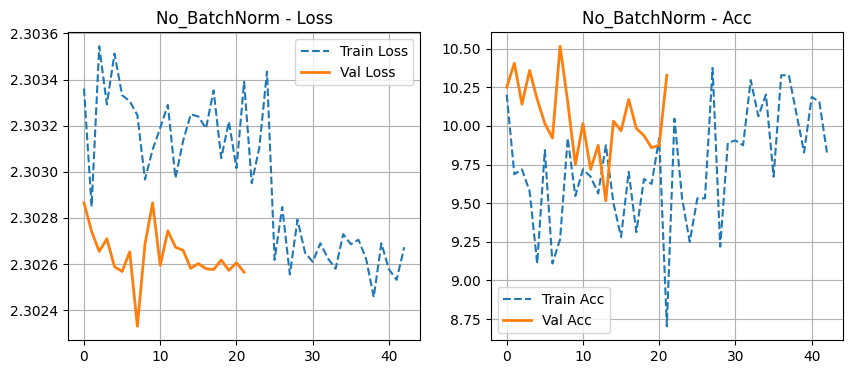


Starting: BatchNorm
>>> [BatchNorm Val] Loss: 2.30283, Acc: 9.66%
[BatchNorm] [Ep: 1, Step: 99] Train Loss: 1.90475, Acc: 27.34%
[BatchNorm] [Ep: 2, Step: 199] Train Loss: 1.61565, Acc: 37.28%
>>> [BatchNorm Val] Loss: 1.45623, Acc: 42.38%
[BatchNorm] [Ep: 3, Step: 299] Train Loss: 1.51365, Acc: 41.59%
[BatchNorm] [Ep: 4, Step: 399] Train Loss: 1.37629, Acc: 48.09%
>>> [BatchNorm Val] Loss: 1.43966, Acc: 45.19%
[BatchNorm] [Ep: 4, Step: 499] Train Loss: 1.30842, Acc: 51.27%
[BatchNorm] [Ep: 5, Step: 599] Train Loss: 1.23653, Acc: 54.78%
>>> [BatchNorm Val] Loss: 1.19477, Acc: 57.91%
[BatchNorm] [Ep: 6, Step: 699] Train Loss: 1.19210, Acc: 57.58%
[BatchNorm] [Ep: 7, Step: 799] Train Loss: 1.10069, Acc: 59.80%
>>> [BatchNorm Val] Loss: 1.14630, Acc: 58.12%
[BatchNorm] [Ep: 8, Step: 899] Train Loss: 1.07394, Acc: 61.77%
[BatchNorm] [Ep: 8, Step: 999] Train Loss: 1.06128, Acc: 63.28%
>>> [BatchNorm Val] Loss: 0.93143, Acc: 67.61%
[BatchNorm] [Ep: 9, Step: 1099] Train Loss: 0.95985, Acc: 6

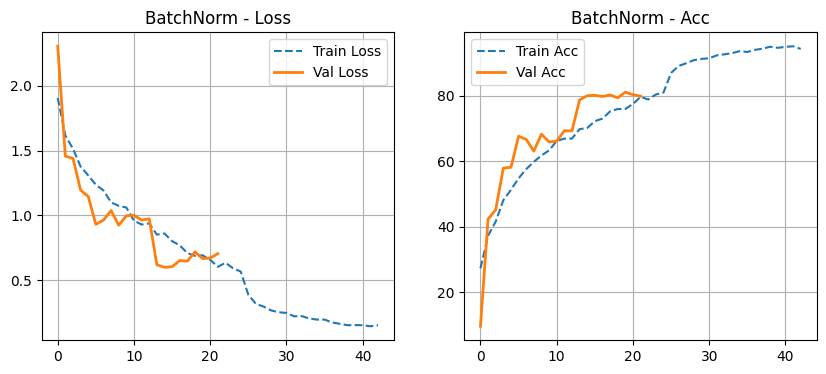


Starting: Augmentation
>>> [Augmentation Val] Loss: 2.30287, Acc: 9.98%
[Augmentation] [Ep: 1, Step: 99] Train Loss: 2.03463, Acc: 23.03%
[Augmentation] [Ep: 2, Step: 199] Train Loss: 1.73322, Acc: 32.83%
>>> [Augmentation Val] Loss: 1.58388, Acc: 41.12%
[Augmentation] [Ep: 3, Step: 299] Train Loss: 1.60474, Acc: 38.06%
[Augmentation] [Ep: 4, Step: 399] Train Loss: 1.52727, Acc: 42.30%
>>> [Augmentation Val] Loss: 1.33843, Acc: 51.17%
[Augmentation] [Ep: 4, Step: 499] Train Loss: 1.43895, Acc: 46.38%
[Augmentation] [Ep: 5, Step: 599] Train Loss: 1.33446, Acc: 50.44%
>>> [Augmentation Val] Loss: 1.10486, Acc: 59.17%
[Augmentation] [Ep: 6, Step: 699] Train Loss: 1.26604, Acc: 53.61%
[Augmentation] [Ep: 7, Step: 799] Train Loss: 1.18474, Acc: 57.06%
>>> [Augmentation Val] Loss: 1.18253, Acc: 58.34%
[Augmentation] [Ep: 8, Step: 899] Train Loss: 1.13929, Acc: 58.42%
[Augmentation] [Ep: 8, Step: 999] Train Loss: 1.09583, Acc: 60.50%
>>> [Augmentation Val] Loss: 1.05285, Acc: 62.09%
[Augment

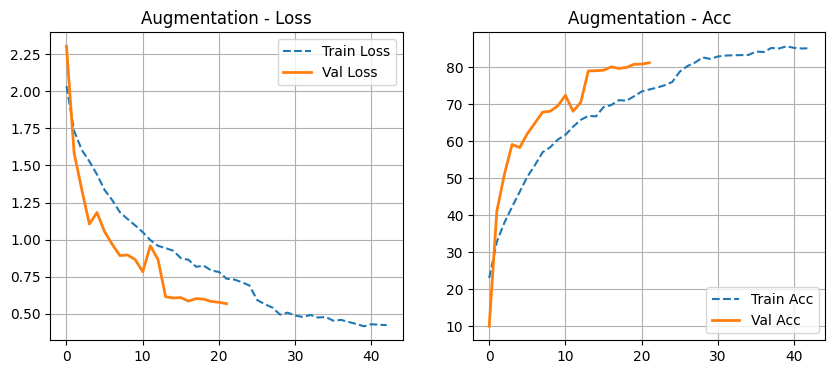


📊 REZULTATE FINALE:


,Model,Hidden1,Hidden2,BatchNorm,Augmentation,Optimizator,LR,Final Val Acc,Final Val Loss
0,No_BatchNorm,2048,512,False,False,sgd,0.0100,10.33%,2.3026
1,BatchNorm,2048,512,True,False,sgd,0.0100,79.81%,0.7056
2,Augmentation,1024,512,True,True,adam,0.0001,81.27%,0.5682



🧩 Matricea de Confuzie pentru: Augmentation (Acc: 81.27%)


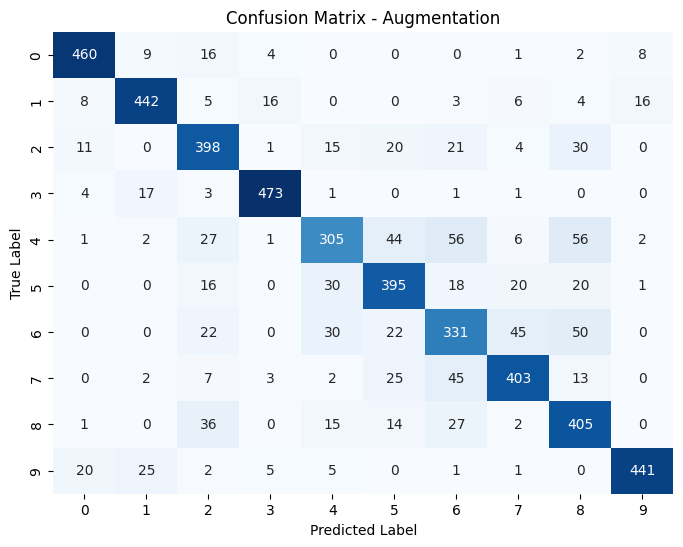


✅ Done! Best model: Augmentation with 81.27% accuracy


In [81]:
experiments = [
    {
        "name": "No_BatchNorm",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 512,
        "opt": "sgd",
        "lr": 0.01,
        "momentum": 0.9,
        "wd": 0.0005,
        "batch_norm": False,
        "dropout_val": 0.5,
        "augmentation": False
    },
    {
        "name": "BatchNorm",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 512,
        "opt": "sgd",
        "lr": 0.01,
        "momentum": 0.9,
        "wd": 0.0005,
        "batch_norm": True,
        "dropout_val": 0.5,
        "augmentation": False
    },
    {
        "name": "Augmentation",
        "input": 512,
        "hidden1": 1024,
        "hidden2": 512,
        "opt": "adam",
        "lr": 0.0001,
        "wd": 0.001,
        "batch_norm": True,
        "dropout_val": 0.5,
        "augmentation": True
    }
]

results_table = []
best_acc = 0.0
best_model_state = None
best_model_name = ""
best_config = {}

for exp in experiments:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    # Creează modelul
    net = MiniVGG(
        num_classes=10,
        in_size=exp['input'],
        hidden_size1=exp['hidden1'],
        hidden_size2=exp['hidden2'],
        use_batch_norm=exp['batch_norm'],
        dropout_val=exp['dropout_val']
    ).to(device)

    # REPARAT: Logica inversată era greșită!
    if exp['augmentation']:
        loader = train_loader_aug  # CU augmentări
    else:
        loader = train_loader  # FĂRĂ augmentări

    # Optimizer
    if exp['opt'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=exp['momentum'], weight_decay=exp['wd'])
    elif exp['opt'] == 'adam':
        optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['wd'])

    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[20, 30], gamma=0.1)

    # REPARAT: Adaugă train_loader ca parametru
    hist = train_engine(net, loader, optimizer, scheduler, num_epochs=35, name=exp['name'])

    # Plot
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_loss'], label='Val Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_acc'], label='Val Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend()
    plt.grid()

    plt.show()

    # Salvare rezultate
    final_acc = hist['val_acc'][-1]
    final_loss = hist['val_loss'][-1]

    # Convert tensor to float dacă e nevoie
    if torch.is_tensor(final_acc):
        final_acc = final_acc.item()
    if torch.is_tensor(final_loss):
        final_loss = final_loss.item()

    results_table.append({
        "Model": exp['name'],
        "Hidden1": exp['hidden1'],
        "Hidden2": exp['hidden2'],
        "BatchNorm": exp['batch_norm'],
        "Augmentation": exp['augmentation'],
        "Optimizator": exp['opt'],
        "LR": exp['lr'],
        "Final Val Acc": f"{final_acc:.2f}%",
        "Final Val Loss": f"{final_loss:.4f}"
    })

    # Salvează cel mai bun model
    if final_acc > best_acc:
        best_acc = final_acc
        best_model_name = exp['name']
        best_config = exp.copy()  # Salvează întreaga configurație
        best_model_state = copy.deepcopy(net.state_dict())

# --- TABEL COMPARATIV ---
print("\n📊 REZULTATE FINALE:")
df = pd.DataFrame(results_table)
display.display(df)

# --- MATRICEA DE CONFUZIE ---
print(f"\n🧩 Matricea de Confuzie pentru: {best_model_name} (Acc: {best_acc:.2f}%)")

# REPARAT: Reconstruiește modelul cu parametrii corecți
final_net = MiniVGG(
    num_classes=10,
    in_size=best_config['input'],
    hidden_size1=best_config['hidden1'],
    hidden_size2=best_config['hidden2'],
    use_batch_norm=best_config['batch_norm'],
    dropout_val=best_config['dropout_val']
).to(device)

final_net.load_state_dict(best_model_state)
final_net.eval()

all_preds = []
all_labels = []

# REPARAT: Folosește test_loader direct, nu test_images
final_test_loader = torch.utils.data.DataLoader(
    test_images,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

with torch.no_grad():
    for inputs, labels in final_test_loader:
        inputs = inputs.to(device)
        outputs = final_net(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Plot confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

print(f"\n✅ Done! Best model: {best_model_name} with {best_acc:.2f}% accuracy")

In [82]:
path_to_zip_file = "/content/land_patches.zip"
directory_to_extract_to = "images"

if not os.path.exists(directory_to_extract_to):
    os.makedirs(directory_to_extract_to)

with zipfile.ZipFile(path_to_zip_file, 'r') as zip_ref:
    zip_ref.extractall(directory_to_extract_to)

## Exploratory data analysis for image classification - land_patches

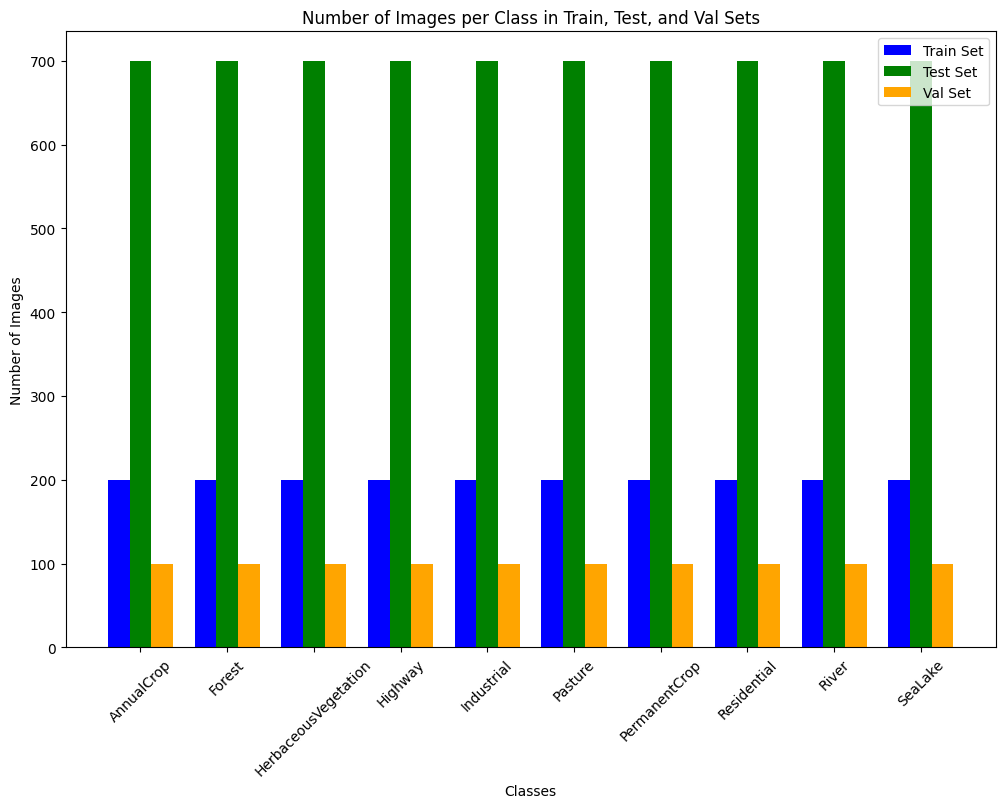

In [83]:
land_patches_train_dir_path = 'images/land_patches/train/'
land_patches_test_dir_path = 'images/land_patches/test/'
land_patches_val_dir_path = 'images/land_patches/val/'

class_names = []
for d in os.listdir(land_patches_train_dir_path):
  if os.path.isdir(os.path.join(land_patches_train_dir_path, d)):
    class_names.append(d)
class_names.sort()

number_classes = {}
for class_name in class_names:
    train_class_dir = os.path.join(land_patches_train_dir_path, class_name)
    test_class_dir = os.path.join(land_patches_test_dir_path, class_name)
    val_class_dir = os.path.join(land_patches_val_dir_path, class_name)

    train_count = len(os.listdir(train_class_dir))
    test_count = len(os.listdir(test_class_dir))
    val_count = len(os.listdir(val_class_dir))

    number_classes[class_name] = {'train_count': train_count, 'test_count': test_count, 'val_count': val_count}

labels = list(number_classes.keys())
train_vals = []
test_vals = []
val_vals = []
for v in number_classes.values():
    train_vals.append(v['train_count'])
    test_vals.append(v['test_count'])
    val_vals.append(v['val_count'])

x = np.arange(len(labels))
width = 0.25

fig = plt.subplots(figsize=(12, 8))
plt.bar(x - width, train_vals, width, label='Train Set', color='blue')
plt.bar(x, test_vals, width, label='Test Set', color='green')
plt.bar(x + width, val_vals, width, label='Val Set', color='orange')

plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train, Test, and Val Sets')
plt.xticks(x, labels, rotation=45)
plt.legend()
plt.show()

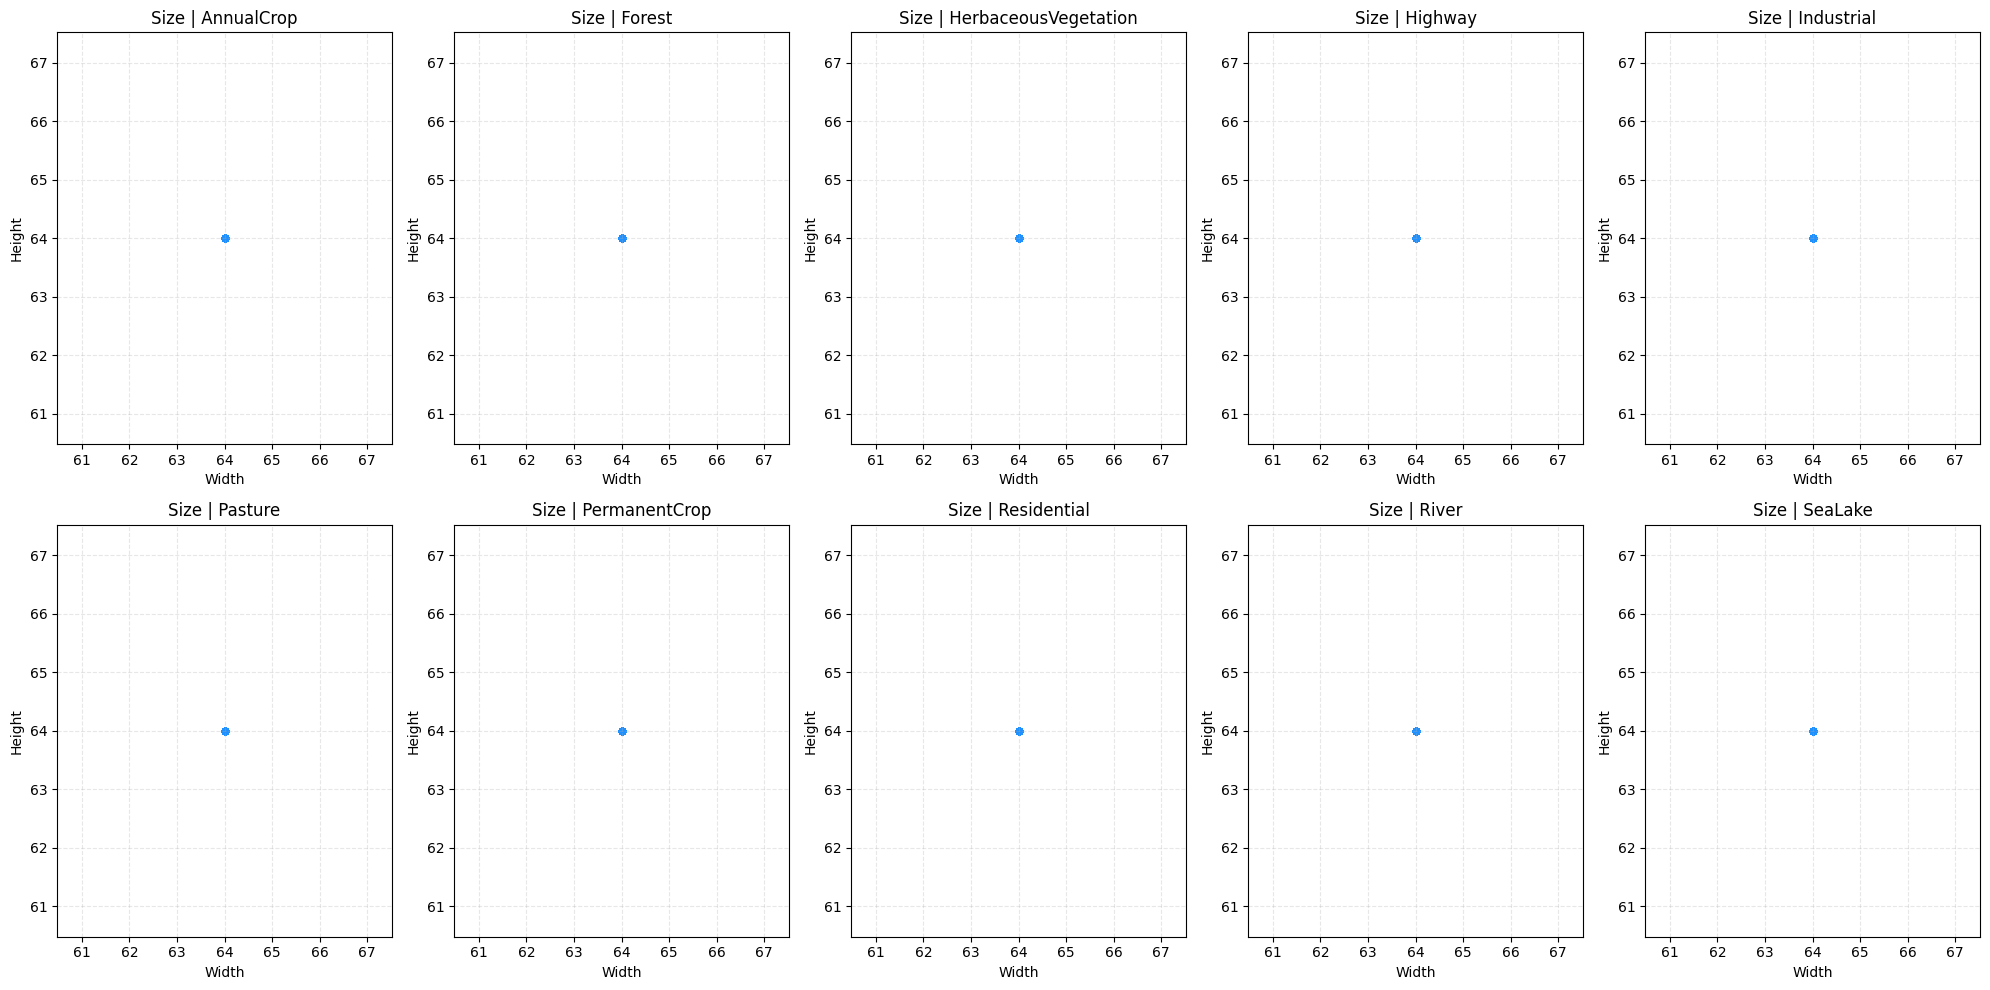

In [84]:
class_data = {}
for class_name in class_names:
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    images = os.listdir(class_dir)

    widths = []
    heights = []

    for img_name in images:
        if img_name.lower().endswith(('.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[class_name] = {'widths': widths, 'heights': heights}


fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))
for idx, class_name in enumerate(class_names):

    width = class_data[class_name]['widths']
    height = class_data[class_name]['heights']

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].scatter(width, height, alpha=0.5, s=20, color='dodgerblue')
    ax[row_idx, col_idx].set_title(f'Size | {class_name}')
    ax[row_idx, col_idx].set_xlabel('Width')
    ax[row_idx, col_idx].set_ylabel('Height')
    ax[row_idx, col_idx].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

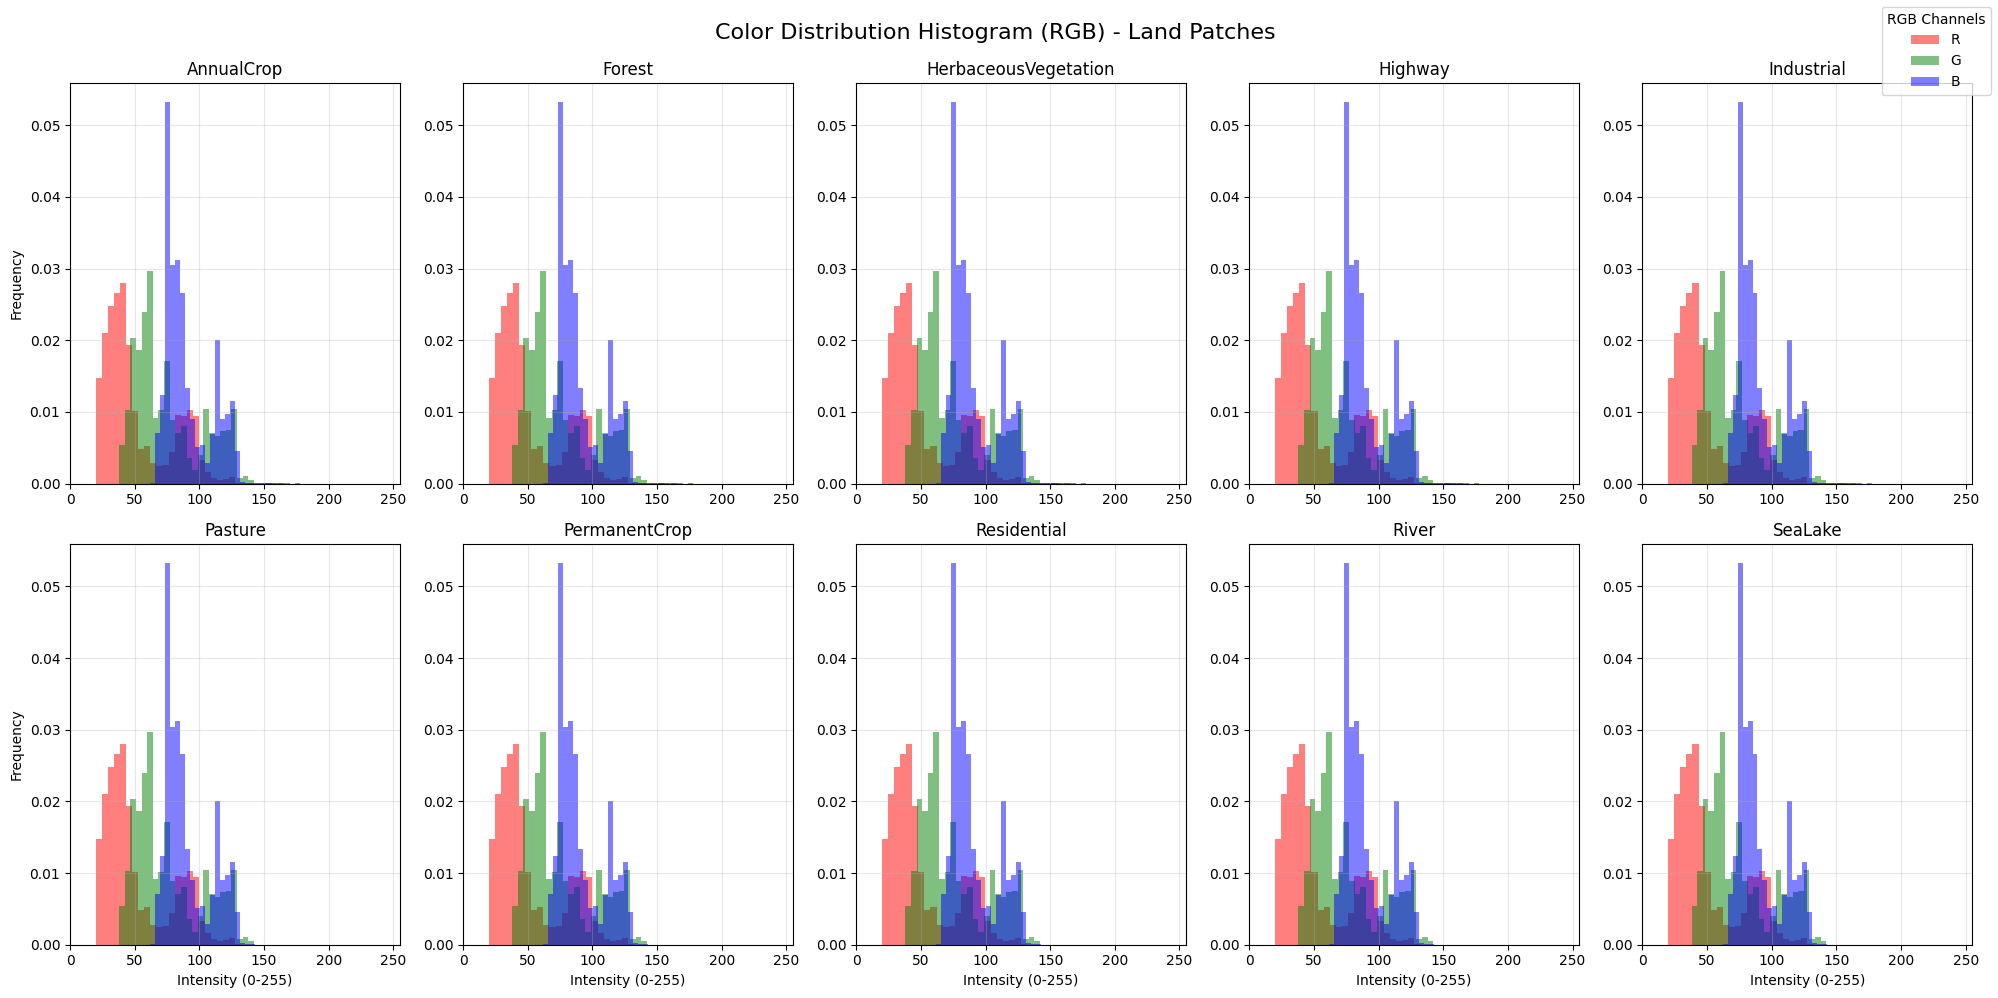

In [85]:
rgb_class = {}

for idx, class_name in enumerate(class_names):
    class_dir = os.path.join(land_patches_train_dir_path, class_name)

    images = os.listdir(class_dir)
    if len(images) > 100:
        images = images[:100]

    all_reds = []
    all_greens = []
    all_blues = []

    for img_name in images:
        if img_name.lower().endswith(('.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path).convert('RGB') as img:
                img_array = np.array(img)
                all_reds.extend(img_array[:, :, 0].flatten())
                all_greens.extend(img_array[:, :, 1].flatten())
                all_blues.extend(img_array[:, :, 2].flatten())

    rgb_class[class_name] = { 'red': all_reds, 'green': all_greens, 'blue': all_blues }

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))
for idx, class_name in enumerate(class_names):
    red = rgb_class[class_name]["red"]
    green = rgb_class[class_name]["green"]
    blue = rgb_class[class_name]["blue"]

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].hist(all_reds, bins=50, color='red', alpha=0.5, label='R', density=True)
    ax[row_idx, col_idx].hist(all_greens, bins=50, color='green', alpha=0.5, label='G', density=True)
    ax[row_idx, col_idx].hist(all_blues, bins=50, color='blue', alpha=0.5, label='B', density=True)
    ax[row_idx, col_idx].set_title(f'{class_name}')
    ax[row_idx, col_idx].set_xlim(0, 255)

    if idx % 5 == 0:
        ax[row_idx, col_idx].set_ylabel('Frequency')
    if idx >= 5:
        ax[row_idx, col_idx].set_xlabel('Intensity (0-255)')

    ax[row_idx, col_idx].grid(True, alpha=0.3)

handles, labels = ax[row_idx, col_idx].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title="RGB Channels")

plt.suptitle("Color Distribution Histogram (RGB) - Land Patches", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

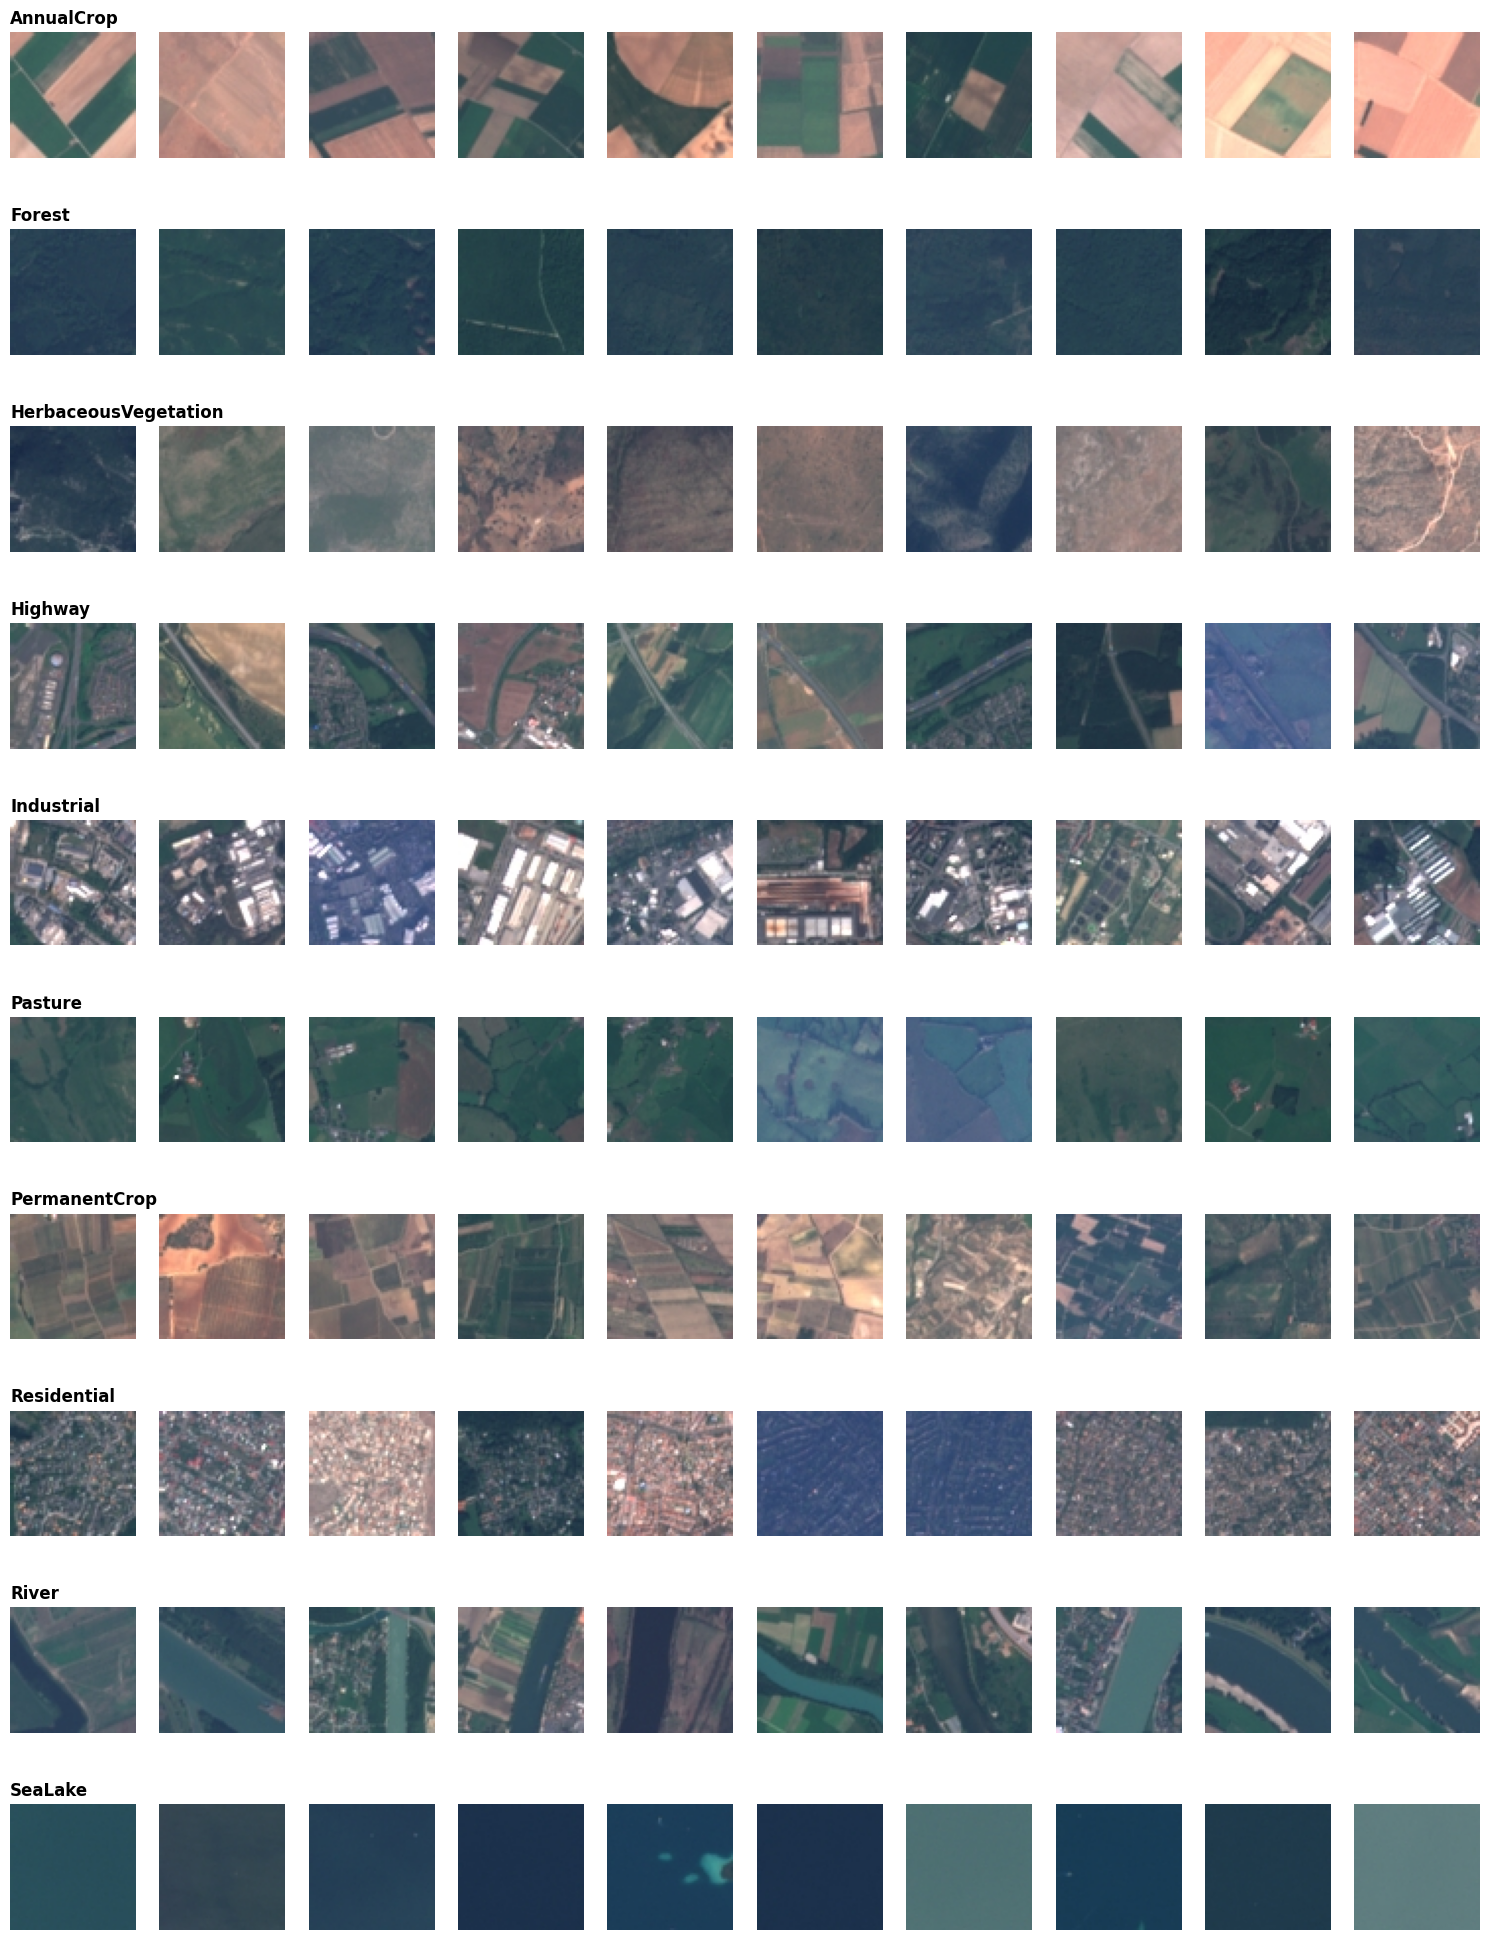

In [86]:
fig, ax = plt.subplots(nrows=len(class_names), ncols=10, figsize=(15, 20))

for row_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    all_imgs = []
    for f in os.listdir(class_dir):
        if f.lower().endswith(('.jpg')):
            all_imgs.append(f)

    current_samples = random.sample(all_imgs, min(len(all_imgs), 10))
    for col_idx, img_name in enumerate(current_samples):
        img_path = os.path.join(class_dir, img_name)
        with Image.open(img_path) as img:
            ax[row_idx, col_idx].imshow(img)
            ax[row_idx, col_idx].axis('off')
            if col_idx == 0:
                ax[row_idx, col_idx].set_title(f'{class_name}', fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

In [87]:
if torch.cuda.is_available():
  device = torch.device("cuda")
else:
  device = torch.device("cpu")

print(f"Running on device: {device}")

train_transform_land = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_transform_land_aug = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

val_transform_land = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

test_transform_land = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_images_land_aug = torchvision.datasets.ImageFolder(root=land_patches_train_dir_path, transform=train_transform_land_aug)
train_images_land = torchvision.datasets.ImageFolder(root=land_patches_train_dir_path, transform=train_transform_land)
val_images_land = torchvision.datasets.ImageFolder(root=land_patches_val_dir_path, transform=val_transform_land)
test_images_land = torchvision.datasets.ImageFolder(root=land_patches_test_dir_path, transform=test_transform_land)

print(f'Size of training labels {len(train_images_land.targets)}')
print(f'Size of augmented training labels {len(train_images_land_aug)}')
print(f'Size of test labels {len(test_images_land.targets)}')
print(f'Size of validation labels {len(val_images_land.targets)}')

Running on device: cuda
Size of training labels 2000
Size of augmented training labels 2000
Size of test labels 7000
Size of validation labels 1000


In [88]:
BATCH_SIZE_TRAIN = 64
BATCH_SIZE_TEST = 64
BATCH_SIZE_VALIDATION = 64
NO_WORKERS = 8
SHUFFLE_DATA = True

train_land_loader = torch.utils.data.DataLoader(train_images_land, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_land_images, batch_train_land_labels) = next(iter(train_land_loader))

print(f'Shape of training images: {batch_train_land_images.size()}')
print(f'Shape of training labels: {batch_train_land_labels.size()}')

train_land_loader_aug = torch.utils.data.DataLoader(train_images_land_aug, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_land_images_aug, batch_train_land_labels_aug) = next(iter(train_land_loader_aug))
print(f'Shape of augmented training images: {batch_train_land_images_aug.size()}')
print(f'Shape of augmented training labels: {batch_train_land_labels_aug.size()}')

val_land_loader = torch.utils.data.DataLoader(val_images_land, batch_size=BATCH_SIZE_VALIDATION, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_val_land_images, batch_val_land_labels) = next(iter(val_land_loader))
print(f'Shape of validation images: {batch_val_land_images.size()}')
print(f'Shape of validation labels: {batch_val_land_labels.size()}')

Shape of training images: torch.Size([64, 3, 64, 64])
Shape of training labels: torch.Size([64])
Shape of augmented training images: torch.Size([64, 3, 64, 64])
Shape of augmented training labels: torch.Size([64])
Shape of validation images: torch.Size([64, 3, 64, 64])
Shape of validation labels: torch.Size([64])


In [89]:
test_land_loader = torch.utils.data.DataLoader(test_images_land, batch_size=BATCH_SIZE_TEST, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)

def loopy_test_loader(dl):
    data_iter = iter(dl)

    while True:
        try:
            yield next(data_iter)
        except StopIteration:
            data_iter = iter(dl)
            yield next(data_iter)

(batch_test_land_images, batch_test_land_labels) = next(iter(test_land_loader))
print(f'Shape of test images: {batch_test_land_images.size()}')
print(f'Shape of test labels: {batch_test_land_labels.size()}')

Shape of test images: torch.Size([64, 3, 64, 64])
Shape of test labels: torch.Size([64])


In [90]:
def plot_losses(loss_list, steps, ct):
    if ct % 1000 == 0:
        display.clear_output(wait=True)

    display.display(plt.gcf())
    plt.plot(steps, loss_list, c='b')
    time.sleep(1.0)

def get_num_params(model):
    num_params = 0
    for params in model.parameters():
        num_params += params.shape.numel()

    return num_params

def top_k_accuracy(k, target, output):
    batch_size = target.size(0)

    _, pred = output.topk(k, 1, True, True)

    pred = pred.t()
    correct = pred.eq(target.to(device).view(1, -1).expand_as(pred))

    correct_k = correct[:k].view(-1).float().sum(0, keepdim=True)
    correct_k.mul_(100.0 / batch_size)

    return correct_k

In [91]:
def train_engine_1(net, train_data_loader, val_data_loader, optimizer, scheduler, num_epochs=35, name="Experiment"):
    # Istoricul ramane la fel
    history = {
        'train_loss': [], 'train_acc': [], 'train_steps': [],
        'val_loss': [], 'val_acc': [], 'val_steps': []
    }

    train_iter = 0
    running_loss = 0.0
    running_acc = 0.0

    # SCHIMBARE: Folosim validation loader aici, nu test!
    val_data_provider = loopy_test_loader(val_data_loader)

    net.train()

    for epoch in range(num_epochs):
        for i, data in enumerate(train_data_loader, 0):

            inputs, labels = data[0].to(device), data[1].to(device)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            running_acc += top_k_accuracy(1, labels, outputs).item()

            # --- RAPORTARE TRAIN ---
            if train_iter % REPORT_TRAIN_EVERY == REPORT_TRAIN_EVERY - 1:
                train_loss = running_loss / REPORT_TRAIN_EVERY
                train_acc = running_acc / REPORT_TRAIN_EVERY

                # Optional: Uncomment print if needed
                # print(f'[{name}] [Ep: {epoch+1}, Step: {train_iter}] Train Loss: {train_loss:.5f}, Acc: {train_acc:.2f}%')

                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['train_steps'].append(train_iter)

                running_loss = 0.0
                running_acc = 0.0

            # --- RAPORTARE VALIDARE (Schimbat din Test in Validare) ---
            if train_iter % REPORT_TEST_EVERY == 0: # Poti redenumi constanta in REPORT_VAL_EVERY daca vrei
                net.eval()
                with torch.no_grad():
                    val_iter = 0 # Renumit din test_iter
                    val_loss_accum = 0.0
                    val_acc_accum = 0.0

                    # Folosim constanta TEST_ITERS (sau poti face una VAL_ITERS)
                    while val_iter < TEST_ITERS:
                        try:
                            val_data = next(val_data_provider)
                        except StopIteration:
                            val_data_provider = loopy_test_loader(val_data_loader)
                            val_data = next(val_data_provider)

                        v_in, v_lbl = val_data[0].to(device), val_data[1].to(device)
                        v_out = net(v_in)

                        val_loss_accum += criterion(v_out, v_lbl).item()
                        val_acc_accum += top_k_accuracy(1, v_lbl, v_out).item()
                        val_iter += 1

                    avg_val_loss = val_loss_accum / TEST_ITERS
                    avg_val_acc = val_acc_accum / TEST_ITERS

                    print(f'>>> [{name} VALIDATION] Loss: {avg_val_loss:.5f}, Acc: {avg_val_acc:.2f}%')

                    history['val_loss'].append(avg_val_loss)
                    history['val_acc'].append(avg_val_acc)
                    history['val_steps'].append(train_iter)

                net.train()

            train_iter += 1

        scheduler.step()

    print(f"Finished: {name}")
    return history

In [92]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, img_size = 64, hidden_size=512, out_size=256, num_classes=10, dropout_val=0.5):
        super(MLP, self).__init__()

        self.in_size = 3 * img_size * img_size

        self.fc1 = nn.Linear(self.in_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, out_size)
        self.fc3 = nn.Linear(out_size, num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout_val)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [93]:
import itertools
import torch
import torch.optim as optim
import pandas as pd

# Definirea grilei
params_mlp = {
    'hidden_size': [256, 512, 1024],
    'dropout_val': [0.3, 0.4, 0.5],
    'lr': [0.01, 0.001],
    'optimizer': ['sgd', 'adam']
}

best_acc_mlp = 0
best_config_mlp = {}
all_results = []

keys = params_mlp.keys()
values = params_mlp.values()

# Calcul total combinații
total_combinations = 1
for v in values: total_combinations *= len(v)

print(f"=== Începe Grid Search pe {total_combinations} combinații folosind VALIDATION SET ===")

for i, combination in enumerate(itertools.product(*values)):
    p = dict(zip(keys, combination))
    exp_name = f"MLP_Exp_{i+1}"

    print(f"\n[{i+1}/{total_combinations}] Rulare {exp_name} cu params: {p}")

    # 1. Init Model
    net = MLP(img_size=64, hidden_size=p['hidden_size'], dropout_val=p['dropout_val']).to(device)

    # 2. Init Optimizer
    if p['optimizer'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=1e-4)
    else:
        optimizer = optim.Adam(net.parameters(), lr=p['lr'], weight_decay=1e-4)

    # 3. Scheduler
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

    # 4. Antrenare -> AICI E MODIFICAREA PRINCIPALA
    # Pasam val_land_loader ca al 3-lea argument
    hist = train_engine_1(
        net=net,
        train_data_loader=train_land_loader,
        val_data_loader=val_land_loader,  # <--- Folosim setul de validare!
        optimizer=optimizer,
        scheduler=scheduler,
        num_epochs=35,
        name=exp_name
    )

    # 5. Evaluare
    final_acc = 0
    if len(hist['val_acc']) > 0:
        final_acc = max(hist['val_acc'])

        result_entry = p.copy()
        result_entry['accuracy'] = final_acc
        result_entry['exp_name'] = exp_name
        all_results.append(result_entry)

        if final_acc > best_acc_mlp:
            best_acc_mlp = final_acc
            best_config_mlp = p
            print(f"--> NEW RECORD (Validation)! Acc: {best_acc_mlp:.2f}% cu {p}")
    else:
        print("Atentie: Nu s-a inregistrat nicio acuratete.")

print("\n" + "="*40)
print(f"FINAL BEST CONFIG (Based on Validation): {best_config_mlp}")
print(f"BEST VALIDATION ACCURACY: {best_acc_mlp:.2f}%")
print("="*40)

if all_results:
    df_results = pd.DataFrame(all_results)
    print("\nTop 5 rezultate:")
    print(df_results.sort_values(by='accuracy', ascending=False).head(5))

=== Începe Grid Search pe 36 combinații folosind VALIDATION SET ===

[1/36] Rulare MLP_Exp_1 cu params: {'hidden_size': 256, 'dropout_val': 0.3, 'lr': 0.01, 'optimizer': 'sgd'}
>>> [MLP_Exp_1 VALIDATION] Loss: 2.29185, Acc: 9.97%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.62232, Acc: 39.98%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.43583, Acc: 51.98%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.36425, Acc: 53.25%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.32601, Acc: 55.12%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.31678, Acc: 56.73%
Finished: MLP_Exp_1
--> NEW RECORD (Validation)! Acc: 56.73% cu {'hidden_size': 256, 'dropout_val': 0.3, 'lr': 0.01, 'optimizer': 'sgd'}

[2/36] Rulare MLP_Exp_2 cu params: {'hidden_size': 256, 'dropout_val': 0.3, 'lr': 0.01, 'optimizer': 'adam'}
>>> [MLP_Exp_2 VALIDATION] Loss: 30.95444, Acc: 11.72%
>>> [MLP_Exp_2 VALIDATION] Loss: 1.98906, Acc: 23.84%
>>> [MLP_Exp_2 VALIDATION] Loss: 1.93022, Acc: 22.98%
>>> [MLP_Exp_2 VALIDATION] Loss: 1.79278, Acc: 29.74%
>>> [MLP_Exp_2 VALIDATION] Loss: 1.7

In [95]:
p = {
    'hidden_size': 1024,
    'dropout_val': 0.3,
    'lr': 0.01,
    'optimizer': 'sgd'
}
net = MLP(img_size=64, hidden_size=p['hidden_size'], dropout_val=p['dropout_val']).to(device)

optimizer = optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

hist = train_engine_1(net, train_land_loader, test_land_loader, optimizer, scheduler, num_epochs=50, name=exp_name)


>>> [MLP_Exp_36 VALIDATION] Loss: 2.29687, Acc: 11.84%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.66364, Acc: 37.14%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.53282, Acc: 45.65%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.38249, Acc: 54.02%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.34342, Acc: 55.09%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.34112, Acc: 55.11%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.36907, Acc: 54.69%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.32911, Acc: 55.14%
Finished: MLP_Exp_36


In [96]:
import torch
import torch.nn as nn

class LeNet(nn.Module):
    def __init__(self, img_size=64, num_classes=10, in_size=512, hidden_size1=1024, hidden_size2=1024, use_batch_norm=False, dropout_val=0.5):
        super(LeNet, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5)
        if use_batch_norm:
            self.bn1 = nn.BatchNorm2d(6)
        else:
            self.bn1 = nn.Identity()

        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        if use_batch_norm:
            self.bn2 = nn.BatchNorm2d(16)
        else:
            self.bn2 = nn.Identity()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.size = img_size - 5 + 1
        self.size = self.size // 2
        self.size = self.size - 5 + 1
        self.size = self.size // 2

        flatten_size = 16 * self.size * self.size

        self.fc1 = nn.Linear(in_features=flatten_size, out_features=hidden_size1)
        self.fc2 = nn.Linear(in_features=hidden_size1, out_features=hidden_size2)
        self.fc3 = nn.Linear(in_features=hidden_size2, out_features=num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout_val)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.pool(x)

        x = self.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [97]:
import itertools
import torch
import torch.optim as optim
import pandas as pd

params_lenet = {
    'hidden_size1': [120, 256],       # Standard LeNet vs Ceva mai mare
    'hidden_size2': [84, 128],        # Standard vs Mai mare
    'dropout_val': [0.3, 0.5],        # Cat de mult 'uitam'
    'use_batch_norm': [True, False],  # Testam daca BN ajuta
    'lr': [0.001],                    # Tinem LR fix pt inceput sa nu explodeze combinatiile
    'optimizer': ['adam', 'sgd']      # Adam e rapid, SGD e precis
}

best_acc_lenet = 0
best_config_lenet = {}
all_results_lenet = []

keys = params_lenet.keys()
values = params_lenet.values()

total_combinations = 1
for v in values: total_combinations *= len(v)

print(f"=== Începe Grid Search LeNet pe {total_combinations} combinații ===")
print(f"Device folosit: {device}")

# 2. Bucla de Grid Search
for i, combination in enumerate(itertools.product(*values)):
    # Facem dictionarul curent (ex: {'hidden_size1': 120, 'optimizer': 'adam', ...})
    p = dict(zip(keys, combination))
    exp_name = f"LeNet_Exp_{i+1}"

    print(f"\n[{i+1}/{total_combinations}] Rulare {exp_name} cu params: {p}")

    # --- A. Initializare Model ---
    # Atentie: in_size nu e folosit in logica ta de flatten, deci il lasam default sau il ignoram.
    # Important e img_size=64 pentru ca logica ta de calcul (self.size) depinde de el.
    net = LeNet(
        img_size=64,
        num_classes=10,
        hidden_size1=p['hidden_size1'],
        hidden_size2=p['hidden_size2'],
        use_batch_norm=p['use_batch_norm'],
        dropout_val=p['dropout_val']
    ).to(device)

    # --- B. Initializare Optimizator ---
    if p['optimizer'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=1e-4)
    else:
        optimizer = optim.Adam(net.parameters(), lr=p['lr'], weight_decay=1e-4)

    # --- C. Scheduler ---
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

    # --- D. Antrenare ---
    # Folosim functia train_engine cu setul de VALIDARE
    hist = train_engine_1(
        net=net,
        train_data_loader=train_land_loader,
        val_data_loader=val_land_loader,  # Validare!
        optimizer=optimizer,
        scheduler=scheduler,
        num_epochs=30,  # 30 epoci sunt suficiente pt LeNet sa arate ce poate
        name=exp_name
    )

    # --- E. Evaluare si Salvare ---
    if len(hist['val_acc']) > 0:
        final_acc = max(hist['val_acc'])

        result_entry = p.copy()
        result_entry['accuracy'] = final_acc
        result_entry['exp_name'] = exp_name
        all_results_lenet.append(result_entry)

        if final_acc > best_acc_lenet:
            best_acc_lenet = final_acc
            best_config_lenet = p
            print(f"--> NEW RECORD (Validation)! Acc: {best_acc_lenet:.2f}% cu {p}")
    else:
        print("Eroare: Nu s-au inregistrat date de validare.")

# 3. Raport Final
print("\n" + "="*40)
print(f"FINAL BEST LENET CONFIG: {best_config_lenet}")
print(f"BEST VALIDATION ACCURACY: {best_acc_lenet:.2f}%")
print("="*40)

# Afisare top 5
if all_results_lenet:
    df_lenet = pd.DataFrame(all_results_lenet)
    print("\nTop 5 rezultate LeNet:")
    print(df_lenet.sort_values(by='accuracy', ascending=False).head(5))


=== Începe Grid Search LeNet pe 32 combinații ===
Device folosit: cuda

[1/32] Rulare LeNet_Exp_1 cu params: {'hidden_size1': 120, 'hidden_size2': 84, 'dropout_val': 0.3, 'use_batch_norm': True, 'lr': 0.001, 'optimizer': 'adam'}
>>> [LeNet_Exp_1 VALIDATION] Loss: 2.30002, Acc: 17.38%
>>> [LeNet_Exp_1 VALIDATION] Loss: 1.45525, Acc: 48.21%
>>> [LeNet_Exp_1 VALIDATION] Loss: 0.84716, Acc: 71.62%
>>> [LeNet_Exp_1 VALIDATION] Loss: 0.73940, Acc: 74.09%
>>> [LeNet_Exp_1 VALIDATION] Loss: 0.73339, Acc: 74.41%
Finished: LeNet_Exp_1
--> NEW RECORD (Validation)! Acc: 74.41% cu {'hidden_size1': 120, 'hidden_size2': 84, 'dropout_val': 0.3, 'use_batch_norm': True, 'lr': 0.001, 'optimizer': 'adam'}

[2/32] Rulare LeNet_Exp_2 cu params: {'hidden_size1': 120, 'hidden_size2': 84, 'dropout_val': 0.3, 'use_batch_norm': True, 'lr': 0.001, 'optimizer': 'sgd'}
>>> [LeNet_Exp_2 VALIDATION] Loss: 2.30503, Acc: 9.56%
>>> [LeNet_Exp_2 VALIDATION] Loss: 1.54676, Acc: 46.27%
>>> [LeNet_Exp_2 VALIDATION] Loss: 1.

In [98]:
p = {
    'hidden_size1': 256,
    'hidden_size2': 84,
    'dropout_val': 0.3,
    'use_batch_norm': True,
    'lr': 0.001,
    'optimizer': 'adam'
}
net = LeNet(img_size=64, num_classes=10, hidden_size1=p['hidden_size1'], hidden_size2=p['hidden_size2'], use_batch_norm=p['use_batch_norm'], dropout_val=p['dropout_val']).to(device)

optimizer = optim.Adam(net.parameters(), lr=p['lr'], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

hist = train_engine_1(net=net, train_data_loader=train_land_loader, val_data_loader=test_land_loader, optimizer=optimizer, scheduler=scheduler, num_epochs=40, name="LeNet_Exp_17")


>>> [LeNet_Exp_17 VALIDATION] Loss: 2.29262, Acc: 12.16%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.95808, Acc: 64.21%
>>> [LeNet_Exp_17 VALIDATION] Loss: 1.01625, Acc: 63.07%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.77563, Acc: 73.82%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.76916, Acc: 75.10%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.76174, Acc: 75.73%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.74530, Acc: 76.48%
Finished: LeNet_Exp_17


>>> [Source_ImageBits_Training Val] Loss: 2.30325, Acc: 9.97%
[Source_ImageBits_Training] [Ep: 1, Step: 99] Train Loss: 2.02223, Acc: 23.41%
[Source_ImageBits_Training] [Ep: 2, Step: 199] Train Loss: 1.71603, Acc: 32.92%
>>> [Source_ImageBits_Training Val] Loss: 1.49693, Acc: 42.88%
[Source_ImageBits_Training] [Ep: 3, Step: 299] Train Loss: 1.57953, Acc: 39.23%
[Source_ImageBits_Training] [Ep: 4, Step: 399] Train Loss: 1.47926, Acc: 43.64%
>>> [Source_ImageBits_Training Val] Loss: 1.25117, Acc: 53.34%
[Source_ImageBits_Training] [Ep: 4, Step: 499] Train Loss: 1.37654, Acc: 48.55%
[Source_ImageBits_Training] [Ep: 5, Step: 599] Train Loss: 1.28875, Acc: 51.70%
>>> [Source_ImageBits_Training Val] Loss: 1.22471, Acc: 53.97%
[Source_ImageBits_Training] [Ep: 6, Step: 699] Train Loss: 1.23656, Acc: 54.61%
[Source_ImageBits_Training] [Ep: 7, Step: 799] Train Loss: 1.16507, Acc: 57.09%
>>> [Source_ImageBits_Training Val] Loss: 1.04850, Acc: 61.91%
[Source_ImageBits_Training] [Ep: 8, Step: 899] 

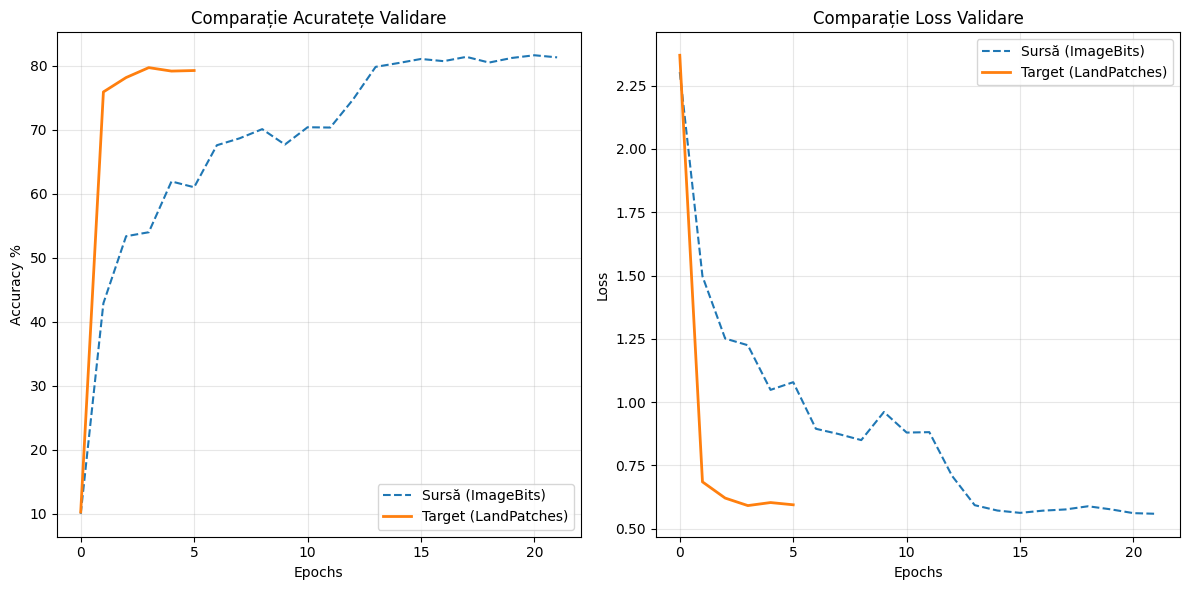


Final Result on LandPatches: 79.24% Accuracy


In [100]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

source_config = {
    "input": 512,
    "hidden1": 1024,
    "hidden2": 512,
    "batch_norm": True,
    "dropout_val": 0.5
}

source_net = MiniVGG(num_classes=10, in_size=source_config['input'], hidden_size1=source_config['hidden1'], hidden_size2=source_config['hidden2'], use_batch_norm=source_config['batch_norm'],dropout_val=source_config['dropout_val']).to(device)
optimizer_source = optim.Adam(source_net.parameters(), lr=0.0001, weight_decay=0.001)
scheduler_source = optim.lr_scheduler.MultiStepLR(optimizer_source, milestones=[20, 30], gamma=0.1)

hist_source = train_engine(
    net=source_net,
    train_data_loader=train_loader_aug,
    optimizer=optimizer_source,
    scheduler=scheduler_source,
    num_epochs=35,
    name="Source_ImageBits_Training"
)

print("\n✅ Antrenare sursă completă. Salvăm greutățile în memorie...")
best_source_weights = copy.deepcopy(source_net.state_dict())


target_net = MiniVGG(
    num_classes=10,
    in_size=source_config['input'],
    hidden_size1=source_config['hidden1'],
    hidden_size2=source_config['hidden2'],
    use_batch_norm=source_config['batch_norm'],
    dropout_val=source_config['dropout_val']
).to(device)

target_net.load_state_dict(best_source_weights)
print("-> Greutățile sursă au fost transferate.")

for name, param in target_net.named_parameters():
    if "fc" not in name:
        param.requires_grad = False

print("-> Straturile convoluționale au fost înghețate (Frozen).")

num_ftrs = target_net.fc3.in_features
target_net.fc3 = nn.Linear(num_ftrs, 10).to(device)

params_to_update = [p for p in target_net.parameters() if p.requires_grad]

optimizer_target = optim.Adam(params_to_update, lr=0.0001, weight_decay=0.001)
scheduler_target = optim.lr_scheduler.MultiStepLR(optimizer_target, milestones=[10, 15], gamma=0.1)

hist_transfer = train_engine_1(
    net=target_net,
    train_data_loader=train_land_loader,
    val_data_loader=test_land_loader,
    optimizer=optimizer_target,
    scheduler=scheduler_target,
    num_epochs=35,
    name="Target_LandPatches_Transfer"
)


plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(hist_source['val_acc'], label='Sursă (ImageBits)', linestyle='--')
plt.plot(hist_transfer['val_acc'], label='Target (LandPatches)', linewidth=2)
plt.title("Comparație Acuratețe Validare")
plt.xlabel("Epochs")
plt.ylabel("Accuracy %")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(hist_source['val_loss'], label='Sursă (ImageBits)', linestyle='--')
plt.plot(hist_transfer['val_loss'], label='Target (LandPatches)', linewidth=2)
plt.title("Comparație Loss Validare")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nFinal Result on LandPatches: {hist_transfer['val_acc'][-1]:.2f}% Accuracy")